# 02 — Controlled Model Deterioration Experiments

## Objective

This notebook studies how a previously valid predictive model behaves when its operating environment changes.

The logistic regression model developed in Notebook 1 is treated as the fixed baseline model. It will **not be retrained** when evaluated in future environments.

Instead, we will generate controlled future populations in which we selectively modify:

- the distribution of model inputs, $P(X)$;
- the relationship between inputs and the outcome, $P(Y \mid X)$;
- or both.

Because the data-generating process is known, we can distinguish between:

1. changes in the environment,
2. statistical drift,
3. calibration deterioration,
4. discrimination deterioration, and
5. overall predictive deterioration.

The credit-risk setting is used only as a controlled experimental environment for studying model risk and model deterioration.

## Experimental Framework

Let the baseline development environment be characterized by:

$
P_0(X)
$

and

$
P_0(Y \mid X).
$

The baseline model is trained under this environment and then frozen.

We subsequently evaluate the same model under future environments indexed by $t$, characterized by:

$
P_t(X)
$

and

$
P_t(Y \mid X).
$

The controlled experiments will separate several types of environmental change.

### Stable Environment

$
P_t(X) \approx P_0(X)
$

and

$
P_t(Y \mid X) \approx P_0(Y \mid X).
$

The model should continue to behave approximately as it did during baseline evaluation.

### Covariate Drift

$
P_t(X) \neq P_0(X)
$

while

$
P_t(Y \mid X) \approx P_0(Y \mid X).
$

The borrower population changes, but the underlying mechanism relating borrower characteristics to default remains unchanged.

### Concept Drift

$
P_t(X) \approx P_0(X)
$

while

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

The borrower population may appear statistically similar to the baseline population, while the relationship between borrower characteristics and default changes.

### Combined Drift

Both distributions change:

$
P_t(X) \neq P_0(X)
$

and

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

This represents a more substantial change in the operating environment.

## Drift Is Not the Same as Model Deterioration

A change in the data distribution does not automatically imply that the model has become unreliable.

Similarly, a model may deteriorate even when conventional input-drift measures detect little change.

We therefore distinguish between:

- **Covariate drift:** change in $P(X)$
- **Concept drift:** change in $P(Y \mid X)$
- **Calibration deterioration:** predicted probabilities no longer correspond well to observed or true event probabilities
- **Discrimination deterioration:** the model becomes worse at ranking high-risk observations above low-risk observations
- **Overall predictive deterioration:** worsening predictive loss or error relative to the baseline environment

These phenomena may occur together, but they are not equivalent.

## Reproducible Experiment Setup

The baseline model is loaded from the serialized artifact created in Notebook 1.

No model fitting or updating is performed in this notebook. The fitted preprocessing and logistic regression components remain fixed throughout all deterioration experiments.

Only the future operating environment will change.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss,
)

from sklearn.calibration import calibration_curve

In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

print(f"Current working directory: {CURRENT_DIR}")
print(f"Project root: {PROJECT_ROOT}")

Current working directory: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\notebooks
Project root: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk


In [3]:
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )

from src.drift import (
    calculate_psi,
    summarize_feature_drift,
)

In [4]:
RANDOM_SEED = 42
N_FUTURE = 50_000

MODEL_FEATURES = [
    "credit_score",
    "debt_to_income",
    "loan_to_income",
    "unemployment_rate",
]

MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

BASELINE_MODEL_PATH = MODELS_DIR / "baseline_model.joblib"

In [5]:
if not BASELINE_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Baseline model artifact was not found at: "
        f"{BASELINE_MODEL_PATH}"
    )

baseline_model = joblib.load(BASELINE_MODEL_PATH)

print(f"Loaded baseline model from: {BASELINE_MODEL_PATH}")
print(type(baseline_model))

Loaded baseline model from: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\models\baseline_model.joblib
<class 'sklearn.pipeline.Pipeline'>


In [6]:
saved_model_features = list(
    baseline_model.feature_names_in_
)

print("Expected features:")
print(MODEL_FEATURES)

print("\nFeatures stored in baseline model:")
print(saved_model_features)

assert saved_model_features == MODEL_FEATURES, (
    "The feature specification in Notebook 2 does not match "
    "the features stored in the baseline model."
)

print("\nBaseline model feature check passed.")

Expected features:
['credit_score', 'debt_to_income', 'loan_to_income', 'unemployment_rate']

Features stored in baseline model:
['credit_score', 'debt_to_income', 'loan_to_income', 'unemployment_rate']

Baseline model feature check passed.


In [7]:
baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logistic_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['credit_score','debt_to_income','loan_to_income','unemployment_rate']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Baseline Data-Generating Process

To construct controlled deterioration experiments, we separate the synthetic environment into two components:

1. **Feature generation**, which determines $P(X)$
2. **Outcome mechanism**, which determines $P(Y \mid X)$

This separation allows future experiments to change one component while holding the other fixed.

For example:

- Covariate drift will modify the feature-generation process while retaining the baseline outcome mechanism.
- Concept drift will retain approximately the same feature-generation process while modifying the outcome mechanism.
- Combined drift will modify both.

The baseline functions below reproduce the environment used to develop the original model.

In [8]:
def generate_baseline_features(n, rng):
    """
    Generate borrower features from the baseline P(X).

    Parameters
    ----------
    n : int
        Number of synthetic borrowers to generate.

    rng : numpy.random.Generator
        Random-number generator used for reproducibility.

    Returns
    -------
    pandas.DataFrame
        Synthetic borrower characteristics.
    """

    age = rng.normal(
        loc=42,
        scale=12,
        size=n,
    )

    age = np.clip(age, 18, 80)
    age = np.round(age).astype(int)

    annual_income = rng.lognormal(
        mean=np.log(70_000),
        sigma=0.45,
        size=n,
    )

    annual_income = np.clip(
        annual_income,
        20_000,
        300_000,
    )

    credit_score = rng.normal(
        loc=700,
        scale=55,
        size=n,
    )

    credit_score = np.clip(
        credit_score,
        500,
        850,
    )

    credit_score = np.round(
        credit_score
    ).astype(int)

    debt_to_income = rng.beta(
        a=2.5,
        b=5.0,
        size=n,
    )

    debt_to_income = np.clip(
        debt_to_income,
        0.02,
        0.90,
    )

    loan_to_income_ratio = rng.uniform(
        low=0.05,
        high=0.60,
        size=n,
    )

    loan_amount = (
        annual_income * loan_to_income_ratio
    )

    loan_amount = np.clip(
        loan_amount,
        2_000,
        75_000,
    )

    unemployment_rate = rng.normal(
        loc=0.045,
        scale=0.005,
        size=n,
    )

    unemployment_rate = np.clip(
        unemployment_rate,
        0.025,
        0.070,
    )

    borrowers = pd.DataFrame(
        {
            "age": age,
            "annual_income": annual_income,
            "credit_score": credit_score,
            "debt_to_income": debt_to_income,
            "loan_amount": loan_amount,
            "unemployment_rate": unemployment_rate,
        }
    )

    borrowers["loan_to_income"] = (
        borrowers["loan_amount"]
        / borrowers["annual_income"]
    )

    return borrowers

In [9]:
def calculate_baseline_true_pd(borrowers):
    """
    Calculate the baseline true probability of default P(Y=1 | X).

    This reproduces the synthetic outcome mechanism used
    in Notebook 1.

    Parameters
    ----------
    borrowers : pandas.DataFrame
        Borrower characteristics.

    Returns
    -------
    pandas.Series
        True probability of default for each borrower.
    """

    credit_score_effect = (
        borrowers["credit_score"] - 700
    ) / 50

    dti_effect = (
        borrowers["debt_to_income"] - 0.33
    ) / 0.15

    loan_burden_effect = (
        borrowers["loan_to_income"] - 0.30
    ) / 0.15

    unemployment_effect = (
        borrowers["unemployment_rate"] - 0.045
    ) / 0.01

    log_odds = (
        -3.2
        - 0.65 * credit_score_effect
        + 1.00 * dti_effect
        + 0.65 * loan_burden_effect
        + 0.45 * unemployment_effect
    )

    true_pd = 1 / (
        1 + np.exp(-log_odds)
    )

    return true_pd

In [10]:
test_rng = np.random.default_rng(12345)

test_borrowers = generate_baseline_features(
    n=5,
    rng=test_rng,
)

test_borrowers

,age,annual_income,credit_score,debt_to_income,loan_amount,unemployment_rate,loan_to_income
0,25,50153.943660,829,0.459564,28143.172841,0.046565,0.561136
1,57,37825.690939,753,0.549937,13254.209293,0.044346,0.350402
2,32,93737.376305,658,0.087759,53029.120458,0.051350,0.565720
3,39,82349.418306,750,0.136906,26536.553829,0.044535,0.322243
4,41,29070.004335,674,0.591052,5830.723398,0.044669,0.200575


In [11]:
test_true_pd = calculate_baseline_true_pd(
    test_borrowers
)

test_true_pd

0    0.056719
1    0.096758
2    0.055633
3    0.006294
4    0.172590
dtype: float64

In [12]:
assert test_true_pd.between(0, 1).all()

print("Baseline true-PD function check passed.")

Baseline true-PD function check passed.


## Stable Future Environment

The first future scenario serves as a control experiment.

A new population of borrowers is generated from the same baseline feature distribution:

$
P_t(X) = P_0(X)
$

and the same baseline outcome mechanism is retained:

$
P_t(Y \mid X) = P_0(Y \mid X).
$

The observations and realized defaults are new random draws, so the future sample will not be identical to the development sample.

If the baseline model remains valid, its future performance should be close to the baseline benchmark, apart from normal sampling variation.

In [13]:
def generate_observed_defaults(true_pd, rng):
    """
    Generate observed binary default outcomes from true probabilities.

    Parameters
    ----------
    true_pd : array-like
        True probability of default for each borrower.

    rng : numpy.random.Generator
        Random-number generator used for reproducibility.

    Returns
    -------
    numpy.ndarray
        Binary default outcomes taking values 0 or 1.
    """

    observed_defaults = rng.binomial(
        n=1,
        p=true_pd,
    )

    return observed_defaults

In [14]:
stable_rng = np.random.default_rng(
    RANDOM_SEED + 1
)

In [15]:
stable_future = generate_baseline_features(
    n=N_FUTURE,
    rng=stable_rng,
)

In [16]:
stable_future.head()

,age,annual_income,credit_score,debt_to_income,loan_amount,unemployment_rate,loan_to_income
0,45,120910.337508,681,0.147718,7497.139256,0.045998,0.062006
1,50,58150.887556,598,0.432358,5271.993320,0.051092,0.090661
2,35,42452.503970,732,0.118290,10531.617880,0.049556,0.248080
3,31,78161.775220,753,0.662630,46727.464151,0.043425,0.597830
4,18,75531.518196,698,0.446599,6877.847315,0.047712,0.091059


In [17]:
stable_future.shape

(50000, 7)

In [18]:
stable_future["true_pd"] = (
    calculate_baseline_true_pd(
        stable_future
    )
)

In [19]:
stable_future[
    [
        "credit_score",
        "debt_to_income",
        "loan_to_income",
        "unemployment_rate",
        "true_pd",
    ]
].head()

,credit_score,debt_to_income,loan_to_income,unemployment_rate,true_pd
0,681,0.147718,0.062006,0.045998,0.005740
1,598,0.432358,0.090661,0.051092,0.138884
2,732,0.118290,0.248080,0.049556,0.006385
3,753,0.662630,0.597830,0.043425,0.388951
4,698,0.446599,0.091059,0.047712,0.039924


In [20]:
stable_future["default"] = (
    generate_observed_defaults(
        true_pd=stable_future["true_pd"],
        rng=stable_rng,
    )
)

In [21]:
stable_future["predicted_pd"] = (
    baseline_model.predict_proba(
        stable_future[MODEL_FEATURES]
    )[:, 1]
)

In [22]:
stable_future[
    [
        "credit_score",
        "debt_to_income",
        "loan_to_income",
        "unemployment_rate",
        "true_pd",
        "predicted_pd",
        "default",
    ]
].head(10)

,credit_score,debt_to_income,loan_to_income,unemployment_rate,true_pd,predicted_pd,default
0,681,0.147718,0.062006,0.045998,0.005740,0.005488,0
1,598,0.432358,0.090661,0.051092,0.138884,0.134899,0
2,732,0.118290,0.248080,0.049556,0.006385,0.006094,0
3,753,0.662630,0.597830,0.043425,0.388951,0.379622,1
4,698,0.446599,0.091059,0.047712,0.039924,0.038060,0
5,724,0.519270,0.128987,0.045034,0.047892,0.045556,0
6,785,0.361760,0.167171,0.042539,0.008329,0.007855,0
7,708,0.217904,0.523239,0.045317,0.044376,0.043055,0
8,681,0.099110,0.562978,0.041313,0.028787,0.028143,0
9,616,0.328630,0.263719,0.045042,0.093429,0.091148,0


In [23]:
assert len(stable_future) == N_FUTURE

assert stable_future["true_pd"].between(
    0, 1
).all()

assert stable_future["predicted_pd"].between(
    0, 1
).all()

assert set(
    stable_future["default"].unique()
).issubset({0, 1})

assert stable_future[
    MODEL_FEATURES
].isna().sum().sum() == 0

print("Stable future scenario checks passed.")

Stable future scenario checks passed.


In [24]:
stable_true_default_rate = (
    stable_future["true_pd"].mean()
)

stable_observed_default_rate = (
    stable_future["default"].mean()
)

stable_mean_predicted_pd = (
    stable_future["predicted_pd"].mean()
)

print(
    f"Average true PD: "
    f"{stable_true_default_rate:.4%}"
)

print(
    f"Observed default rate: "
    f"{stable_observed_default_rate:.4%}"
)

print(
    f"Average predicted PD: "
    f"{stable_mean_predicted_pd:.4%}"
)

Average true PD: 9.2327%
Observed default rate: 9.0420%
Average predicted PD: 9.0062%


## Scenario Evaluation Framework

Each future environment is evaluated using the same set of metrics.

The evaluation considers several distinct dimensions of model reliability:

- **ROC AUC** measures discrimination: how well the model ranks higher-risk borrowers above lower-risk borrowers.
- **Brier Score** measures squared probability error relative to observed binary outcomes.
- **Log Loss** measures probabilistic prediction quality and penalizes confident incorrect predictions strongly.
- **Calibration Error** measures disagreement between predicted probabilities and observed default frequencies across probability groups.
- **MAE vs. True PD** directly compares model predictions with the known synthetic probability of default.

The final metric is available because the experiment uses a controlled synthetic data-generating process. It provides an oracle measure of probability error that would generally not be observable in a real production environment.

In [25]:
def evaluate_scenario(data, scenario_name):
    """
    Evaluate model performance for one simulated environment.

    Parameters
    ----------
    data : pandas.DataFrame
        Scenario data containing:
        - default
        - true_pd
        - predicted_pd

    scenario_name : str
        Descriptive name of the scenario.

    Returns
    -------
    pandas.DataFrame
        One-row summary of scenario-level performance metrics.
    """

    required_columns = {
        "default",
        "true_pd",
        "predicted_pd",
    }

    missing_columns = (
        required_columns - set(data.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    y_true = data["default"]
    y_pred = data["predicted_pd"]
    true_pd = data["true_pd"]

    roc_auc = roc_auc_score(
        y_true,
        y_pred,
    )

    brier = brier_score_loss(
        y_true,
        y_pred,
    )

    logloss = log_loss(
        y_true,
        y_pred,
    )

    (
        fraction_of_positives,
        mean_predicted_probability,
    ) = calibration_curve(
        y_true,
        y_pred,
        n_bins=10,
        strategy="quantile",
    )

    calibration_error = np.mean(
        np.abs(
            fraction_of_positives
            - mean_predicted_probability
        )
    )

    mae_vs_true_pd = np.mean(
        np.abs(
            y_pred - true_pd
        )
    )

    results = pd.DataFrame(
        {
            "scenario": [scenario_name],
            "n": [len(data)],
            "true_pd_mean": [true_pd.mean()],
            "observed_default_rate": [
                y_true.mean()
            ],
            "predicted_pd_mean": [
                y_pred.mean()
            ],
            "roc_auc": [roc_auc],
            "brier_score": [brier],
            "log_loss": [logloss],
            "calibration_error": [
                calibration_error
            ],
            "mae_vs_true_pd": [
                mae_vs_true_pd
            ],
        }
    )

    return results

In [26]:
stable_results = evaluate_scenario(
    data=stable_future,
    scenario_name="Stable",
)

stable_results

,scenario,n,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,50000,0.092327,0.09042,0.090062,0.838288,0.066717,0.232585,0.001895,0.002266


In [27]:
stable_results[
    [
        "scenario",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,0.8383,0.0667,0.2326,0.0019,0.0023


In [28]:
assert stable_results.shape[0] == 1

assert (
    stable_results.loc[0, "scenario"]
    == "Stable"
)

assert 0 <= stable_results.loc[
    0, "roc_auc"
] <= 1

assert stable_results.loc[
    0, "brier_score"
] >= 0

assert stable_results.loc[
    0, "log_loss"
] >= 0

assert stable_results.loc[
    0, "calibration_error"
] >= 0

assert stable_results.loc[
    0, "mae_vs_true_pd"
] >= 0

print(
    "Stable scenario evaluation checks passed."
)

Stable scenario evaluation checks passed.


## Covariate Drift Scenario

This scenario changes the distribution of borrower characteristics while preserving the original relationship between borrower characteristics and default.

Formally:

$
P_t(X) \neq P_0(X)
$

while:

$
P_t(Y \mid X) = P_0(Y \mid X).
$

The future population is constructed to have:

- credit scores approximately 20 points lower than the baseline population;
- debt-to-income ratios approximately 0.05 higher than the baseline population.

Other parts of the feature-generation process remain unchanged.

The original baseline true-PD function is retained. Therefore, any change in the overall default rate is caused by the changing borrower population rather than by a change in the conditional default mechanism.

In [29]:
def generate_covariate_drift_features(n, rng):
    """
    Generate borrower features under controlled covariate drift.

    The underlying baseline feature generator is retained,
    but credit scores are shifted downward and debt-to-income
    ratios are shifted upward.

    This changes P(X) without changing P(Y | X).

    Parameters
    ----------
    n : int
        Number of synthetic borrowers.

    rng : numpy.random.Generator
        Random-number generator.

    Returns
    -------
    pandas.DataFrame
        Borrower characteristics under covariate drift.
    """

    borrowers = generate_baseline_features(
        n=n,
        rng=rng,
    )

    borrowers["credit_score"] = np.clip(
        borrowers["credit_score"] - 20,
        500,
        850,
    ).astype(int)

    borrowers["debt_to_income"] = np.clip(
        borrowers["debt_to_income"] + 0.05,
        0.02,
        0.90,
    )

    return borrowers

In [30]:
covariate_rng = np.random.default_rng(
    RANDOM_SEED + 2
)

In [31]:
covariate_future = (
    generate_covariate_drift_features(
        n=N_FUTURE,
        rng=covariate_rng,
    )
)

In [32]:
covariate_future.shape

(50000, 7)

In [33]:
feature_comparison = pd.DataFrame(
    {
        "Stable Mean": stable_future[
            MODEL_FEATURES
        ].mean(),
        "Covariate Drift Mean": covariate_future[
            MODEL_FEATURES
        ].mean(),
    }
)

feature_comparison["Difference"] = (
    feature_comparison["Covariate Drift Mean"]
    - feature_comparison["Stable Mean"]
)

feature_comparison

,Stable Mean,Covariate Drift Mean,Difference
credit_score,699.756560,680.245740,-19.510820
debt_to_income,0.333742,0.382310,0.048568
loan_to_income,0.323854,0.323557,-0.000298
unemployment_rate,0.044989,0.044976,-0.000013


In [34]:
credit_score_shift = (
    covariate_future["credit_score"].mean()
    - stable_future["credit_score"].mean()
)

dti_shift = (
    covariate_future["debt_to_income"].mean()
    - stable_future["debt_to_income"].mean()
)

print(
    f"Mean credit-score shift: "
    f"{credit_score_shift:.2f}"
)

print(
    f"Mean DTI shift: "
    f"{dti_shift:.4f}"
)

Mean credit-score shift: -19.51
Mean DTI shift: 0.0486


In [35]:
covariate_future["true_pd"] = (
    calculate_baseline_true_pd(
        covariate_future
    )
)

In [36]:
covariate_future["default"] = (
    generate_observed_defaults(
        true_pd=covariate_future["true_pd"],
        rng=covariate_rng,
    )
)

In [37]:
covariate_future["predicted_pd"] = (
    baseline_model.predict_proba(
        covariate_future[MODEL_FEATURES]
    )[:, 1]
)

In [38]:
assert len(covariate_future) == N_FUTURE

assert covariate_future["true_pd"].between(
    0, 1
).all()

assert covariate_future[
    "predicted_pd"
].between(
    0, 1
).all()

assert set(
    covariate_future["default"].unique()
).issubset({0, 1})

print(
    "Covariate drift scenario checks passed."
)

Covariate drift scenario checks passed.


In [39]:
print(
    f"Average true PD: "
    f"{covariate_future['true_pd'].mean():.4%}"
)

print(
    f"Observed default rate: "
    f"{covariate_future['default'].mean():.4%}"
)

print(
    f"Average predicted PD: "
    f"{covariate_future['predicted_pd'].mean():.4%}"
)

Average true PD: 13.8739%
Observed default rate: 13.8820%
Average predicted PD: 13.5847%


In [40]:
covariate_results = evaluate_scenario(
    data=covariate_future,
    scenario_name="Covariate Drift",
)

covariate_results[
    [
        "scenario",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Covariate Drift,0.83,0.0923,0.3067,0.0043,0.0029


In [41]:
scenario_results = pd.concat(
    [
        stable_results,
        covariate_results,
    ],
    ignore_index=True,
)

scenario_results

,scenario,n,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,50000,0.092327,0.09042,0.090062,0.838288,0.066717,0.232585,0.001895,0.002266
1,Covariate Drift,50000,0.138739,0.13882,0.135847,0.830004,0.092295,0.306731,0.004276,0.002892


In [42]:
performance_comparison = scenario_results[
    [
        "scenario",
        "true_pd_mean",
        "observed_default_rate",
        "predicted_pd_mean",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].copy()

performance_comparison.round(4)

,scenario,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,0.0923,0.0904,0.0901,0.8383,0.0667,0.2326,0.0019,0.0023
1,Covariate Drift,0.1387,0.1388,0.1358,0.8300,0.0923,0.3067,0.0043,0.0029


In [43]:
stable_metric_row = (
    scenario_results
    .loc[
        scenario_results["scenario"] == "Stable"
    ]
    .iloc[0]
)

covariate_metric_row = (
    scenario_results
    .loc[
        scenario_results["scenario"]
        == "Covariate Drift"
    ]
    .iloc[0]
)

In [44]:
metric_changes = pd.Series(
    {
        "ROC AUC Change":
            covariate_metric_row["roc_auc"]
            - stable_metric_row["roc_auc"],

        "Brier Score Change":
            covariate_metric_row["brier_score"]
            - stable_metric_row["brier_score"],

        "Log Loss Change":
            covariate_metric_row["log_loss"]
            - stable_metric_row["log_loss"],

        "Calibration Error Change":
            covariate_metric_row["calibration_error"]
            - stable_metric_row["calibration_error"],

        "MAE vs. True PD Change":
            covariate_metric_row["mae_vs_true_pd"]
            - stable_metric_row["mae_vs_true_pd"],
    }
)

metric_changes.round(4)

ROC AUC Change             -0.0083
Brier Score Change          0.0256
Log Loss Change             0.0741
Calibration Error Change    0.0024
MAE vs. True PD Change      0.0006
dtype: float64

### Interpretation of Covariate Drift

The covariate-drift scenario produces a substantially different borrower population and a higher overall default-risk level.

However, because the conditional relationship $P(Y \mid X)$ remains unchanged, input drift alone does not necessarily imply model deterioration.

The relevant question is whether the frozen model continues to produce accurate rankings and probability estimates under the shifted population.

In [45]:
assert covariate_results.shape[0] == 1

assert (
    covariate_results.loc[0, "scenario"]
    == "Covariate Drift"
)

assert len(scenario_results) == 2

assert set(
    scenario_results["scenario"]
) == {
    "Stable",
    "Covariate Drift",
}

print(
    "Covariate drift evaluation checks passed."
)

Covariate drift evaluation checks passed.


## Concept Drift Scenario

The concept-drift scenario isolates a change in the relationship between borrower characteristics and default while holding the borrower population fixed.

The feature values are copied directly from the Stable scenario. Therefore, the empirical distribution of model inputs is identical between the Stable and Concept Drift environments:

$
P_t(X) = P_0(X)
$

within this controlled experiment.

The outcome mechanism is then changed by increasing the baseline log-odds of default while retaining the original feature coefficients.

Thus:

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

This scenario represents a change in underlying default risk that is not visible from changes in the monitored model inputs alone.

In [46]:
CONCEPT_INTERCEPT_SHIFT = 0.60

In [47]:
def calculate_concept_drift_true_pd(
    borrowers,
    intercept_shift=CONCEPT_INTERCEPT_SHIFT,
):
    """
    Calculate true PD under controlled concept drift.

    The baseline feature relationships remain unchanged, but
    the log-odds of default are shifted upward by a constant.

    This changes P(Y | X) without changing P(X).

    Parameters
    ----------
    borrowers : pandas.DataFrame
        Borrower characteristics.

    intercept_shift : float
        Additive shift applied to baseline log-odds.

    Returns
    -------
    pandas.Series
        True probability of default under concept drift.
    """

    baseline_pd = calculate_baseline_true_pd(
        borrowers
    )

    baseline_log_odds = np.log(
        baseline_pd / (1 - baseline_pd)
    )

    concept_log_odds = (
        baseline_log_odds
        + intercept_shift
    )

    concept_true_pd = 1 / (
        1 + np.exp(-concept_log_odds)
    )

    return concept_true_pd

In [48]:
concept_future = stable_future[
    [
        "age",
        "annual_income",
        "credit_score",
        "debt_to_income",
        "loan_amount",
        "unemployment_rate",
        "loan_to_income",
    ]
].copy()

In [49]:
feature_values_identical = np.array_equal(
    stable_future[MODEL_FEATURES].to_numpy(),
    concept_future[MODEL_FEATURES].to_numpy(),
)

print(
    f"Model feature values identical: "
    f"{feature_values_identical}"
)

Model feature values identical: True


In [50]:
assert feature_values_identical

print(
    "Concept drift input-distribution check passed."
)

Concept drift input-distribution check passed.


In [51]:
concept_future["true_pd"] = (
    calculate_concept_drift_true_pd(
        concept_future
    )
)

In [52]:
pd_comparison = pd.DataFrame(
    {
        "stable_true_pd":
            stable_future["true_pd"],
        "concept_true_pd":
            concept_future["true_pd"],
    }
)

pd_comparison["pd_change"] = (
    pd_comparison["concept_true_pd"]
    - pd_comparison["stable_true_pd"]
)

pd_comparison.head(10)

,stable_true_pd,concept_true_pd,pd_change
0,0.005740,0.010409,0.004670
1,0.138884,0.227129,0.088246
2,0.006385,0.011574,0.005189
3,0.388951,0.537001,0.148050
4,0.039924,0.070434,0.030510
5,0.047892,0.083959,0.036067
6,0.008329,0.015074,0.006745
7,0.044376,0.078011,0.033636
8,0.028787,0.051240,0.022454
9,0.093429,0.158095,0.064666


In [53]:
print(
    f"Stable average true PD: "
    f"{stable_future['true_pd'].mean():.4%}"
)

print(
    f"Concept-drift average true PD: "
    f"{concept_future['true_pd'].mean():.4%}"
)

print(
    f"Average borrower-level PD increase: "
    f"{pd_comparison['pd_change'].mean():.4%}"
)

Stable average true PD: 9.2327%
Concept-drift average true PD: 14.0610%
Average borrower-level PD increase: 4.8283%


In [54]:
concept_rng = np.random.default_rng(
    RANDOM_SEED + 3
)

In [55]:
concept_future["default"] = (
    generate_observed_defaults(
        true_pd=concept_future["true_pd"],
        rng=concept_rng,
    )
)

In [56]:
concept_future["predicted_pd"] = (
    baseline_model.predict_proba(
        concept_future[MODEL_FEATURES]
    )[:, 1]
)

In [57]:
max_prediction_difference = np.max(
    np.abs(
        concept_future["predicted_pd"]
        - stable_future["predicted_pd"]
    )
)

print(
    f"Maximum prediction difference "
    f"vs. Stable: "
    f"{max_prediction_difference}"
)

Maximum prediction difference vs. Stable: 0.0


In [58]:
assert max_prediction_difference == 0.0

print(
    "Frozen-model prediction check passed."
)

Frozen-model prediction check passed.


In [59]:
assert len(concept_future) == N_FUTURE

assert concept_future["true_pd"].between(
    0, 1
).all()

assert concept_future[
    "predicted_pd"
].between(
    0, 1
).all()

assert set(
    concept_future["default"].unique()
).issubset({0, 1})

assert (
    concept_future["true_pd"]
    > stable_future["true_pd"]
).all()

print(
    "Concept drift scenario checks passed."
)

Concept drift scenario checks passed.


In [60]:
print(
    f"Average true PD: "
    f"{concept_future['true_pd'].mean():.4%}"
)

print(
    f"Observed default rate: "
    f"{concept_future['default'].mean():.4%}"
)

print(
    f"Average predicted PD: "
    f"{concept_future['predicted_pd'].mean():.4%}"
)

Average true PD: 14.0610%
Observed default rate: 14.1120%
Average predicted PD: 9.0062%


In [61]:
concept_results = evaluate_scenario(
    data=concept_future,
    scenario_name="Concept Drift",
)

concept_results[
    [
        "scenario",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Concept Drift,0.8316,0.0988,0.3273,0.0511,0.0505


In [62]:
scenario_results = pd.concat(
    [
        stable_results,
        covariate_results,
        concept_results,
    ],
    ignore_index=True,
)

scenario_results[
    [
        "scenario",
        "true_pd_mean",
        "observed_default_rate",
        "predicted_pd_mean",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,0.0923,0.0904,0.0901,0.8383,0.0667,0.2326,0.0019,0.0023
1,Covariate Drift,0.1387,0.1388,0.1358,0.8300,0.0923,0.3067,0.0043,0.0029
2,Concept Drift,0.1406,0.1411,0.0901,0.8316,0.0988,0.3273,0.0511,0.0505


In [63]:
comparison_metrics = [
    "roc_auc",
    "brier_score",
    "log_loss",
    "calibration_error",
    "mae_vs_true_pd",
]

In [64]:
stable_reference = (
    scenario_results
    .loc[
        scenario_results["scenario"] == "Stable",
        comparison_metrics,
    ]
    .iloc[0]
)

In [65]:
deterioration_vs_stable = (
    scenario_results[
        ["scenario"] + comparison_metrics
    ]
    .copy()
)

for metric in comparison_metrics:
    deterioration_vs_stable[
        f"{metric}_change"
    ] = (
        deterioration_vs_stable[metric]
        - stable_reference[metric]
    )

deterioration_vs_stable.round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd,roc_auc_change,brier_score_change,log_loss_change,calibration_error_change,mae_vs_true_pd_change
0,Stable,0.8383,0.0667,0.2326,0.0019,0.0023,0.0000,0.0000,0.0000,0.0000,0.0000
1,Covariate Drift,0.8300,0.0923,0.3067,0.0043,0.0029,-0.0083,0.0256,0.0741,0.0024,0.0006
2,Concept Drift,0.8316,0.0988,0.3273,0.0511,0.0505,-0.0067,0.0320,0.0947,0.0492,0.0483


In [66]:
metric_change_summary = pd.DataFrame(
    {
        "Covariate Drift": {
            metric:
                covariate_results.loc[0, metric]
                - stable_results.loc[0, metric]
            for metric in comparison_metrics
        },
        "Concept Drift": {
            metric:
                concept_results.loc[0, metric]
                - stable_results.loc[0, metric]
            for metric in comparison_metrics
        },
    }
)

metric_change_summary.round(4)

,Covariate Drift,Concept Drift
roc_auc,-0.0083,-0.0067
brier_score,0.0256,0.0320
log_loss,0.0741,0.0947
calibration_error,0.0024,0.0492
mae_vs_true_pd,0.0006,0.0483


In [67]:
scenario_results[
    "mean_pd_gap"
] = (
    scenario_results["predicted_pd_mean"]
    - scenario_results["true_pd_mean"]
)

scenario_results[
    [
        "scenario",
        "true_pd_mean",
        "predicted_pd_mean",
        "mean_pd_gap",
    ]
].round(4)

,scenario,true_pd_mean,predicted_pd_mean,mean_pd_gap
0,Stable,0.0923,0.0901,-0.0023
1,Covariate Drift,0.1387,0.1358,-0.0029
2,Concept Drift,0.1406,0.0901,-0.0505


### Interpretation of Concept Drift

The Concept Drift scenario holds the model inputs exactly fixed relative to the Stable environment while changing the true conditional default mechanism.

Therefore, conventional monitoring of the model-input distributions would detect no change in this controlled experiment.

The frozen model also produces exactly the same predictions as in the Stable scenario because it receives exactly the same input values.

However, the true probability of default has changed. As a result, the model's probability estimates can become materially inaccurate even though the input data appear stable.

This illustrates the distinction between:

$
P(X)
$

and:

$
P(Y \mid X).
$

Stable input distributions do not guarantee that a previously valid model remains calibrated or reliable.

In [68]:
assert concept_results.shape[0] == 1

assert (
    concept_results.loc[0, "scenario"]
    == "Concept Drift"
)

assert len(scenario_results) == 3

assert set(
    scenario_results["scenario"]
) == {
    "Stable",
    "Covariate Drift",
    "Concept Drift",
}

print(
    "Concept drift evaluation checks passed."
)

Concept drift evaluation checks passed.


## Input Drift Monitoring

We now compare each future environment with the Stable reference environment using univariate input-drift measures.

The objective is to determine whether monitoring $P(X)$ alone can distinguish the controlled scenarios.

Three statistics are used:

- Population Stability Index (PSI)
- Kolmogorov-Smirnov (KS) statistic
- Wasserstein distance

The Stable environment is used as the reference distribution.

Under the controlled experiment:

- Covariate Drift should produce measurable feature-distribution changes.
- Concept Drift should produce no input-distribution change because it uses exactly the same feature observations as the Stable environment.

In [69]:
covariate_input_drift = (
    summarize_feature_drift(
        reference_data=stable_future,
        current_data=covariate_future,
        features=MODEL_FEATURES,
    )
)

covariate_input_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,680.2457,-19.5108,0.1204,0.1418,19.5108
1,debt_to_income,0.3337,0.3823,0.0486,0.1120,0.1119,0.0486
2,loan_to_income,0.3239,0.3236,-0.0003,0.0004,0.0051,0.0008
3,unemployment_rate,0.0450,0.0450,-0.0000,0.0002,0.0053,0.0000


In [70]:
concept_input_drift = (
    summarize_feature_drift(
        reference_data=stable_future,
        current_data=concept_future,
        features=MODEL_FEATURES,
    )
)

concept_input_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,699.7566,0.0,0.0,0.0,0.0
1,debt_to_income,0.3337,0.3337,0.0,0.0,0.0,0.0
2,loan_to_income,0.3239,0.3239,0.0,0.0,0.0,0.0
3,unemployment_rate,0.0450,0.0450,0.0,0.0,0.0,0.0


In [71]:
assert np.allclose(
    concept_input_drift["mean_shift"],
    0.0,
)

assert np.allclose(
    concept_input_drift["psi"],
    0.0,
)

assert np.allclose(
    concept_input_drift["ks_statistic"],
    0.0,
)

assert np.allclose(
    concept_input_drift[
        "wasserstein_distance"
    ],
    0.0,
)

print(
    "Concept drift input-monitoring "
    "blind-spot check passed."
)

Concept drift input-monitoring blind-spot check passed.


In [72]:
input_drift_comparison = pd.concat(
    [
        covariate_input_drift.assign(
            scenario="Covariate Drift"
        ),
        concept_input_drift.assign(
            scenario="Concept Drift"
        ),
    ],
    ignore_index=True,
)

input_drift_comparison[
    [
        "scenario",
        "feature",
        "psi",
        "ks_statistic",
        "wasserstein_distance",
    ]
].round(4)

,scenario,feature,psi,ks_statistic,wasserstein_distance
0,Covariate Drift,credit_score,0.1204,0.1418,19.5108
1,Covariate Drift,debt_to_income,0.1120,0.1119,0.0486
2,Covariate Drift,loan_to_income,0.0004,0.0051,0.0008
3,Covariate Drift,unemployment_rate,0.0002,0.0053,0.0000
4,Concept Drift,credit_score,0.0000,0.0000,0.0000
5,Concept Drift,debt_to_income,0.0000,0.0000,0.0000
6,Concept Drift,loan_to_income,0.0000,0.0000,0.0000
7,Concept Drift,unemployment_rate,0.0000,0.0000,0.0000


In [73]:
stable_input_drift = (
    summarize_feature_drift(
        reference_data=stable_future,
        current_data=stable_future,
        features=MODEL_FEATURES,
    )
)

stable_input_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,699.7566,0.0,0.0,0.0,0.0
1,debt_to_income,0.3337,0.3337,0.0,0.0,0.0,0.0
2,loan_to_income,0.3239,0.3239,0.0,0.0,0.0,0.0
3,unemployment_rate,0.0450,0.0450,0.0,0.0,0.0,0.0


In [74]:
assert np.allclose(
    stable_input_drift["psi"],
    0.0,
)

assert np.allclose(
    stable_input_drift["ks_statistic"],
    0.0,
)

assert np.allclose(
    stable_input_drift[
        "wasserstein_distance"
    ],
    0.0,
)

print(
    "Stable input-drift reference check passed."
)

Stable input-drift reference check passed.


In [75]:
def summarize_scenario_input_drift(
    drift_table,
    scenario_name,
):
    """
    Summarize feature-level input drift at the scenario level.

    Parameters
    ----------
    drift_table : pandas.DataFrame
        Output from summarize_feature_drift().

    scenario_name : str
        Name of the simulated environment.

    Returns
    -------
    pandas.DataFrame
        One-row summary of input-drift magnitude.
    """

    summary = pd.DataFrame(
        {
            "scenario": [scenario_name],
            "max_psi": [
                drift_table["psi"].max()
            ],
            "mean_psi": [
                drift_table["psi"].mean()
            ],
            "max_ks": [
                drift_table[
                    "ks_statistic"
                ].max()
            ],
            "mean_ks": [
                drift_table[
                    "ks_statistic"
                ].mean()
            ],
        }
    )

    return summary

In [76]:
stable_drift_summary = (
    summarize_scenario_input_drift(
        stable_input_drift,
        "Stable",
    )
)

covariate_drift_summary = (
    summarize_scenario_input_drift(
        covariate_input_drift,
        "Covariate Drift",
    )
)

concept_drift_summary = (
    summarize_scenario_input_drift(
        concept_input_drift,
        "Concept Drift",
    )
)

In [77]:
scenario_drift_summary = pd.concat(
    [
        stable_drift_summary,
        covariate_drift_summary,
        concept_drift_summary,
    ],
    ignore_index=True,
)

scenario_drift_summary.round(4)

,scenario,max_psi,mean_psi,max_ks,mean_ks
0,Stable,0.0000,0.0000,0.0000,0.000
1,Covariate Drift,0.1204,0.0583,0.1418,0.066
2,Concept Drift,0.0000,0.0000,0.0000,0.000


In [78]:
monitoring_summary = pd.merge(
    scenario_drift_summary,
    scenario_results,
    on="scenario",
    how="inner",
)

In [79]:
monitoring_summary[
    [
        "scenario",
        "max_psi",
        "max_ks",
        "true_pd_mean",
        "predicted_pd_mean",
        "roc_auc",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,max_psi,max_ks,true_pd_mean,predicted_pd_mean,roc_auc,calibration_error,mae_vs_true_pd
0,Stable,0.0000,0.0000,0.0923,0.0901,0.8383,0.0019,0.0023
1,Covariate Drift,0.1204,0.1418,0.1387,0.1358,0.8300,0.0043,0.0029
2,Concept Drift,0.0000,0.0000,0.1406,0.0901,0.8316,0.0511,0.0505


In [80]:
monitoring_summary[
    "mean_pd_gap_pp"
] = (
    monitoring_summary["predicted_pd_mean"]
    - monitoring_summary["true_pd_mean"]
) * 100

In [81]:
monitoring_summary[
    [
        "scenario",
        "true_pd_mean",
        "predicted_pd_mean",
        "mean_pd_gap_pp",
    ]
].round(4)

,scenario,true_pd_mean,predicted_pd_mean,mean_pd_gap_pp
0,Stable,0.0923,0.0901,-0.2266
1,Covariate Drift,0.1387,0.1358,-0.2892
2,Concept Drift,0.1406,0.0901,-5.0549


### Monitoring Interpretation

The controlled scenarios demonstrate that input-distribution drift and model deterioration are related but distinct phenomena.

In the Covariate Drift scenario, monitored borrower characteristics change substantially, producing clear input-drift signals. However, the underlying relationship $P(Y \mid X)$ remains unchanged, and the frozen model continues to approximate the true synthetic probabilities closely.

In the Concept Drift scenario, the model-input observations are identical to the Stable environment. Consequently, input-drift measures report no change. Nevertheless, the true conditional probability of default changes, causing substantial deterioration in calibration and probability accuracy.

Therefore, monitoring $P(X)$ alone is not sufficient to establish whether a model remains valid.

In [82]:
assert len(monitoring_summary) == 3

assert set(
    monitoring_summary["scenario"]
) == {
    "Stable",
    "Covariate Drift",
    "Concept Drift",
}

assert (
    monitoring_summary.loc[
        monitoring_summary["scenario"]
        == "Concept Drift",
        "max_psi",
    ].iloc[0]
    == 0.0
)

assert (
    monitoring_summary.loc[
        monitoring_summary["scenario"]
        == "Covariate Drift",
        "max_psi",
    ].iloc[0]
    > 0.0
)

print(
    "Unified monitoring summary checks passed."
)

Unified monitoring summary checks passed.


## Combined Drift Scenario

The Combined Drift scenario changes both the distribution of model inputs and the conditional relationship between inputs and default.

Formally:

$
P_t(X) \neq P_0(X)
$

and:

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

To preserve a controlled experimental design, the Combined Drift scenario uses exactly the same borrower characteristics as the Covariate Drift scenario.

The Concept Drift outcome mechanism is then applied to those borrowers.

Therefore:

- Covariate Drift and Combined Drift have identical $X$;
- Stable and Concept Drift have identical $X$;
- Stable and Covariate Drift use the baseline $P(Y \mid X)$;
- Concept Drift and Combined Drift use the shifted $P(Y \mid X)$.

In [83]:
combined_future = covariate_future[
    [
        "age",
        "annual_income",
        "credit_score",
        "debt_to_income",
        "loan_amount",
        "unemployment_rate",
        "loan_to_income",
    ]
].copy()

In [84]:
combined_features_identical = np.array_equal(
    covariate_future[
        MODEL_FEATURES
    ].to_numpy(),
    combined_future[
        MODEL_FEATURES
    ].to_numpy(),
)

print(
    f"Combined vs. Covariate feature values identical: "
    f"{combined_features_identical}"
)

Combined vs. Covariate feature values identical: True


In [85]:
assert combined_features_identical

print(
    "Combined drift feature-distribution check passed."
)

Combined drift feature-distribution check passed.


In [86]:
combined_future["true_pd"] = (
    calculate_concept_drift_true_pd(
        combined_future
    )
)

In [87]:
combined_pd_comparison = pd.DataFrame(
    {
        "covariate_true_pd":
            covariate_future["true_pd"],
        "combined_true_pd":
            combined_future["true_pd"],
    }
)

combined_pd_comparison[
    "pd_change"
] = (
    combined_pd_comparison[
        "combined_true_pd"
    ]
    - combined_pd_comparison[
        "covariate_true_pd"
    ]
)

combined_pd_comparison.head(10)

,covariate_true_pd,combined_true_pd,pd_change
0,0.381143,0.528793,0.147650
1,0.015883,0.028568,0.012685
2,0.123011,0.203556,0.080544
3,0.022913,0.040978,0.018065
4,0.096202,0.162445,0.066242
5,0.016714,0.030043,0.013328
6,0.070504,0.121428,0.050924
7,0.071813,0.123557,0.051744
8,0.274192,0.407705,0.133514
9,0.034714,0.061498,0.026784


In [88]:
assert (
    combined_future["true_pd"]
    > covariate_future["true_pd"]
).all()

print(
    "Combined drift true-PD shift check passed."
)

Combined drift true-PD shift check passed.


In [89]:
print(
    f"Covariate-drift average true PD: "
    f"{covariate_future['true_pd'].mean():.4%}"
)

print(
    f"Combined-drift average true PD: "
    f"{combined_future['true_pd'].mean():.4%}"
)

print(
    f"Average borrower-level PD increase: "
    f"{combined_pd_comparison['pd_change'].mean():.4%}"
)

Covariate-drift average true PD: 13.8739%
Combined-drift average true PD: 20.2352%
Average borrower-level PD increase: 6.3614%


In [90]:
combined_rng = np.random.default_rng(
    RANDOM_SEED + 4
)

In [91]:
combined_future["default"] = (
    generate_observed_defaults(
        true_pd=combined_future["true_pd"],
        rng=combined_rng,
    )
)

In [92]:
combined_future["predicted_pd"] = (
    baseline_model.predict_proba(
        combined_future[
            MODEL_FEATURES
        ]
    )[:, 1]
)

In [93]:
max_combined_prediction_difference = np.max(
    np.abs(
        combined_future["predicted_pd"]
        - covariate_future["predicted_pd"]
    )
)

print(
    f"Maximum prediction difference "
    f"vs. Covariate Drift: "
    f"{max_combined_prediction_difference}"
)

Maximum prediction difference vs. Covariate Drift: 0.0


In [94]:
assert (
    max_combined_prediction_difference
    == 0.0
)

print(
    "Combined drift frozen-model "
    "prediction check passed."
)

Combined drift frozen-model prediction check passed.


In [95]:
print(
    f"Average true PD: "
    f"{combined_future['true_pd'].mean():.4%}"
)

print(
    f"Observed default rate: "
    f"{combined_future['default'].mean():.4%}"
)

print(
    f"Average predicted PD: "
    f"{combined_future['predicted_pd'].mean():.4%}"
)

Average true PD: 20.2352%
Observed default rate: 20.3160%
Average predicted PD: 13.5847%


In [96]:
combined_input_drift = (
    summarize_feature_drift(
        reference_data=stable_future,
        current_data=combined_future,
        features=MODEL_FEATURES,
    )
)

combined_input_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,680.2457,-19.5108,0.1204,0.1418,19.5108
1,debt_to_income,0.3337,0.3823,0.0486,0.1120,0.1119,0.0486
2,loan_to_income,0.3239,0.3236,-0.0003,0.0004,0.0051,0.0008
3,unemployment_rate,0.0450,0.0450,-0.0000,0.0002,0.0053,0.0000


In [97]:
for metric in [
    "mean_shift",
    "psi",
    "ks_statistic",
    "wasserstein_distance",
]:
    assert np.allclose(
        combined_input_drift[metric],
        covariate_input_drift[metric],
    )

print(
    "Combined and Covariate input-drift "
    "statistics are identical."
)

Combined and Covariate input-drift statistics are identical.


In [98]:
assert len(combined_future) == N_FUTURE

assert combined_future[
    "true_pd"
].between(
    0, 1
).all()

assert combined_future[
    "predicted_pd"
].between(
    0, 1
).all()

assert set(
    combined_future[
        "default"
    ].unique()
).issubset({0, 1})

print(
    "Combined drift scenario checks passed."
)

Combined drift scenario checks passed.


In [99]:
combined_results = evaluate_scenario(
    data=combined_future,
    scenario_name="Combined Drift",
)

combined_results[
    [
        "scenario",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Combined Drift,0.8237,0.1279,0.4068,0.0673,0.0665


In [100]:
scenario_results = pd.concat(
    [
        stable_results,
        covariate_results,
        concept_results,
        combined_results,
    ],
    ignore_index=True,
)

In [101]:
scenario_results[
    [
        "scenario",
        "true_pd_mean",
        "observed_default_rate",
        "predicted_pd_mean",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Stable,0.0923,0.0904,0.0901,0.8383,0.0667,0.2326,0.0019,0.0023
1,Covariate Drift,0.1387,0.1388,0.1358,0.8300,0.0923,0.3067,0.0043,0.0029
2,Concept Drift,0.1406,0.1411,0.0901,0.8316,0.0988,0.3273,0.0511,0.0505
3,Combined Drift,0.2024,0.2032,0.1358,0.8237,0.1279,0.4068,0.0673,0.0665


In [102]:
combined_drift_summary = (
    summarize_scenario_input_drift(
        combined_input_drift,
        "Combined Drift",
    )
)

In [103]:
scenario_drift_summary = pd.concat(
    [
        stable_drift_summary,
        covariate_drift_summary,
        concept_drift_summary,
        combined_drift_summary,
    ],
    ignore_index=True,
)

scenario_drift_summary.round(4)

,scenario,max_psi,mean_psi,max_ks,mean_ks
0,Stable,0.0000,0.0000,0.0000,0.000
1,Covariate Drift,0.1204,0.0583,0.1418,0.066
2,Concept Drift,0.0000,0.0000,0.0000,0.000
3,Combined Drift,0.1204,0.0583,0.1418,0.066


In [104]:
monitoring_summary = pd.merge(
    scenario_drift_summary,
    scenario_results,
    on="scenario",
    how="inner",
)

In [105]:
monitoring_summary[
    "mean_pd_gap_pp"
] = (
    monitoring_summary["predicted_pd_mean"]
    - monitoring_summary["true_pd_mean"]
) * 100

In [106]:
monitoring_summary[
    [
        "scenario",
        "max_psi",
        "max_ks",
        "true_pd_mean",
        "predicted_pd_mean",
        "mean_pd_gap_pp",
        "roc_auc",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,max_psi,max_ks,true_pd_mean,predicted_pd_mean,mean_pd_gap_pp,roc_auc,calibration_error,mae_vs_true_pd
0,Stable,0.0000,0.0000,0.0923,0.0901,-0.2266,0.8383,0.0019,0.0023
1,Covariate Drift,0.1204,0.1418,0.1387,0.1358,-0.2892,0.8300,0.0043,0.0029
2,Concept Drift,0.0000,0.0000,0.1406,0.0901,-5.0549,0.8316,0.0511,0.0505
3,Combined Drift,0.1204,0.1418,0.2024,0.1358,-6.6506,0.8237,0.0673,0.0665


In [107]:
paired_metrics = [
    "roc_auc",
    "brier_score",
    "log_loss",
    "calibration_error",
    "mae_vs_true_pd",
]

In [108]:
concept_effect_baseline_x = pd.Series(
    {
        metric:
            concept_results.loc[0, metric]
            - stable_results.loc[0, metric]
        for metric in paired_metrics
    },
    name="Concept effect | Baseline X",
)

In [109]:
concept_effect_shifted_x = pd.Series(
    {
        metric:
            combined_results.loc[0, metric]
            - covariate_results.loc[0, metric]
        for metric in paired_metrics
    },
    name="Concept effect | Shifted X",
)

In [110]:
concept_effect_comparison = pd.concat(
    [
        concept_effect_baseline_x,
        concept_effect_shifted_x,
    ],
    axis=1,
)

concept_effect_comparison.round(4)

,Concept effect | Baseline X,Concept effect | Shifted X
roc_auc,-0.0067,-0.0063
brier_score,0.0320,0.0356
log_loss,0.0947,0.1001
calibration_error,0.0492,0.0630
mae_vs_true_pd,0.0483,0.0636


In [111]:
covariate_effect_baseline_concept = pd.Series(
    {
        metric:
            covariate_results.loc[0, metric]
            - stable_results.loc[0, metric]
        for metric in paired_metrics
    },
    name="Covariate effect | Baseline Y|X",
)

In [112]:
covariate_effect_shifted_concept = pd.Series(
    {
        metric:
            combined_results.loc[0, metric]
            - concept_results.loc[0, metric]
        for metric in paired_metrics
    },
    name="Covariate effect | Shifted Y|X",
)

In [113]:
covariate_effect_comparison = pd.concat(
    [
        covariate_effect_baseline_concept,
        covariate_effect_shifted_concept,
    ],
    axis=1,
)

covariate_effect_comparison.round(4)

,Covariate effect | Baseline Y|X,Covariate effect | Shifted Y|X
roc_auc,-0.0083,-0.0079
brier_score,0.0256,0.0291
log_loss,0.0741,0.0795
calibration_error,0.0024,0.0163
mae_vs_true_pd,0.0006,0.0160


### Completed Controlled Drift Experiment

The four scenarios form a controlled $2 \times 2$ experimental structure in which the feature distribution $P(X)$ and conditional outcome relationship $P(Y \mid X)$ can be changed independently.

This enables paired comparisons that isolate the effects of each form of environmental change.

- **Stable vs. Concept Drift** holds the feature observations fixed and changes only $P(Y \mid X)$.
- **Covariate Drift vs. Combined Drift** also holds the feature observations fixed and changes only $P(Y \mid X)$.
- **Stable vs. Covariate Drift** retains the baseline $P(Y \mid X)$ while changing $P(X)$.
- **Concept Drift vs. Combined Drift** retains the shifted $P(Y \mid X)$ while changing $P(X)$.

This structure demonstrates why input drift and model deterioration should be monitored as distinct phenomena rather than treated as interchangeable signals.

In [114]:
assert len(scenario_results) == 4
assert len(scenario_drift_summary) == 4
assert len(monitoring_summary) == 4

expected_scenarios = {
    "Stable",
    "Covariate Drift",
    "Concept Drift",
    "Combined Drift",
}

assert set(
    monitoring_summary["scenario"]
) == expected_scenarios

In [115]:
covariate_max_psi = monitoring_summary.loc[
    monitoring_summary["scenario"]
    == "Covariate Drift",
    "max_psi",
].iloc[0]

combined_max_psi = monitoring_summary.loc[
    monitoring_summary["scenario"]
    == "Combined Drift",
    "max_psi",
].iloc[0]

assert np.isclose(
    covariate_max_psi,
    combined_max_psi,
)

In [116]:
stable_max_psi = monitoring_summary.loc[
    monitoring_summary["scenario"]
    == "Stable",
    "max_psi",
].iloc[0]

concept_max_psi = monitoring_summary.loc[
    monitoring_summary["scenario"]
    == "Concept Drift",
    "max_psi",
].iloc[0]

assert np.isclose(
    stable_max_psi,
    concept_max_psi,
)

print(
    "Complete 2x2 drift experiment checks passed."
)

Complete 2x2 drift experiment checks passed.


## Visualizing Drift and Model Deterioration

The controlled experiments show that changes in the input distribution and deterioration in model validity are not equivalent.

The following figures compare input-drift signals with measures of model performance and probability accuracy across the four environments.

In [117]:
plot_data = monitoring_summary[
    [
        "scenario",
        "max_psi",
        "mae_vs_true_pd",
    ]
].copy()

plot_data

,scenario,max_psi,mae_vs_true_pd
0,Stable,0.00000,0.002266
1,Covariate Drift,0.12042,0.002892
2,Concept Drift,0.00000,0.050549
3,Combined Drift,0.12042,0.066506


Saved figure to: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\drift_vs_model_deterioration.png


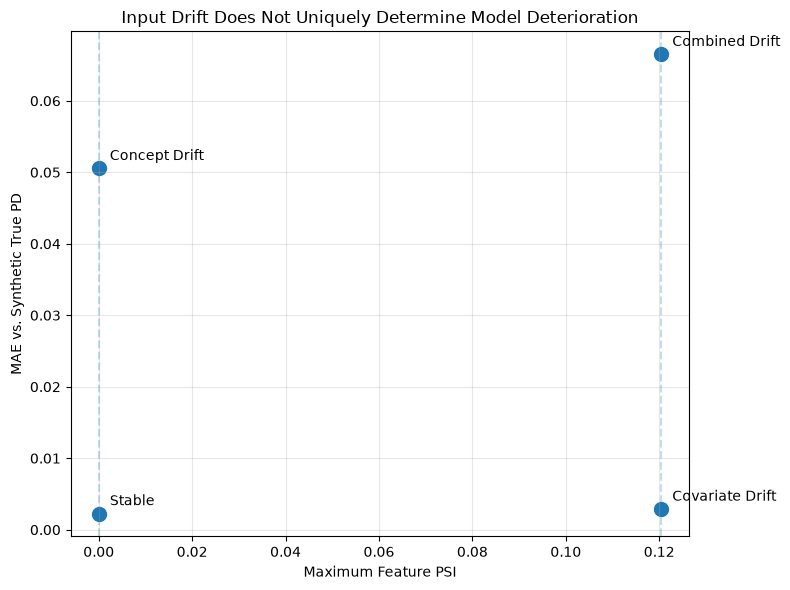

In [118]:
fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    plot_data["max_psi"],
    plot_data["mae_vs_true_pd"],
    s=100,
)

for _, row in plot_data.iterrows():
    ax.annotate(
        row["scenario"],
        (
            row["max_psi"],
            row["mae_vs_true_pd"],
        ),
        xytext=(8, 6),
        textcoords="offset points",
    )

for psi_value in sorted(
    plot_data["max_psi"].unique()
):
    ax.axvline(
        x=psi_value,
        linestyle="--",
        alpha=0.25,
    )

ax.set_xlabel(
    "Maximum Feature PSI"
)

ax.set_ylabel(
    "MAE vs. Synthetic True PD"
)

ax.set_title(
    "Input Drift Does Not Uniquely Determine Model Deterioration"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

figure_path = (
    FIGURES_DIR
    / "drift_vs_model_deterioration.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved figure to: {figure_path}"
)

plt.show()

In [119]:
pd_level_plot_data = monitoring_summary[
    [
        "scenario",
        "true_pd_mean",
        "predicted_pd_mean",
    ]
].copy()

pd_level_plot_data

,scenario,true_pd_mean,predicted_pd_mean
0,Stable,0.092327,0.090062
1,Covariate Drift,0.138739,0.135847
2,Concept Drift,0.140610,0.090062
3,Combined Drift,0.202352,0.135847


In [120]:
pd_level_plot_data[
    "true_pd_percent"
] = (
    pd_level_plot_data["true_pd_mean"]
    * 100
)

pd_level_plot_data[
    "predicted_pd_percent"
] = (
    pd_level_plot_data["predicted_pd_mean"]
    * 100
)

In [121]:
pd_level_plot_data[
    [
        "scenario",
        "true_pd_percent",
        "predicted_pd_percent",
    ]
].round(2)

,scenario,true_pd_percent,predicted_pd_percent
0,Stable,9.23,9.01
1,Covariate Drift,13.87,13.58
2,Concept Drift,14.06,9.01
3,Combined Drift,20.24,13.58


Saved figure to: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\true_vs_predicted_pd_by_scenario.png


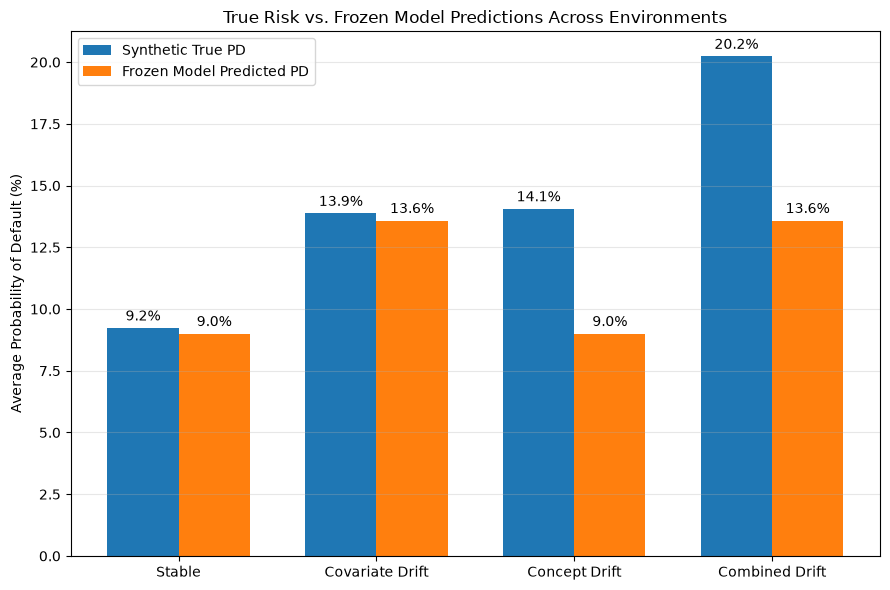

In [122]:
x = np.arange(
    len(pd_level_plot_data)
)

bar_width = 0.36

fig, ax = plt.subplots(
    figsize=(9, 6)
)

true_bars = ax.bar(
    x - bar_width / 2,
    pd_level_plot_data[
        "true_pd_percent"
    ],
    width=bar_width,
    label="Synthetic True PD",
)

predicted_bars = ax.bar(
    x + bar_width / 2,
    pd_level_plot_data[
        "predicted_pd_percent"
    ],
    width=bar_width,
    label="Frozen Model Predicted PD",
)

ax.set_xticks(x)

ax.set_xticklabels(
    pd_level_plot_data["scenario"]
)

ax.set_ylabel(
    "Average Probability of Default (%)"
)

ax.set_title(
    "True Risk vs. Frozen Model Predictions Across Environments"
)

ax.legend()

ax.bar_label(
    true_bars,
    fmt="%.1f%%",
    padding=3,
)

ax.bar_label(
    predicted_bars,
    fmt="%.1f%%",
    padding=3,
)

ax.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "true_vs_predicted_pd_by_scenario.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved figure to: {figure_path}"
)

plt.show()

### Calibration Across Environments

Average predicted risk can hide where probability errors occur across the risk distribution.

Calibration curves compare the model's mean predicted probability with the observed default frequency among borrowers receiving similar predictions.

A well-calibrated model should remain close to the 45-degree perfect-calibration line.

The same frozen model is evaluated across all four environments using identical calibration methodology.

In [123]:
def get_calibration_points(
    data,
    n_bins=10,
):
    """
    Return observed and predicted default rates
    for quantile-based calibration bins.
    """

    (
        observed_rate,
        predicted_rate,
    ) = calibration_curve(
        data["default"],
        data["predicted_pd"],
        n_bins=n_bins,
        strategy="quantile",
    )

    return pd.DataFrame(
        {
            "predicted_rate": predicted_rate,
            "observed_rate": observed_rate,
        }
    )

In [124]:
stable_calibration = get_calibration_points(
    stable_future
)

covariate_calibration = get_calibration_points(
    covariate_future
)

concept_calibration = get_calibration_points(
    concept_future
)

combined_calibration = get_calibration_points(
    combined_future
)

In [125]:
stable_calibration

,predicted_rate,observed_rate
0,0.004088,0.0024
1,0.009223,0.0096
2,0.015342,0.0154
3,0.023391,0.0244
4,0.034293,0.0342
5,0.049909,0.0448
6,0.072942,0.0750
7,0.110066,0.1138
8,0.180772,0.1848
9,0.400592,0.3998


Saved figure to: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\calibration_by_scenario.png


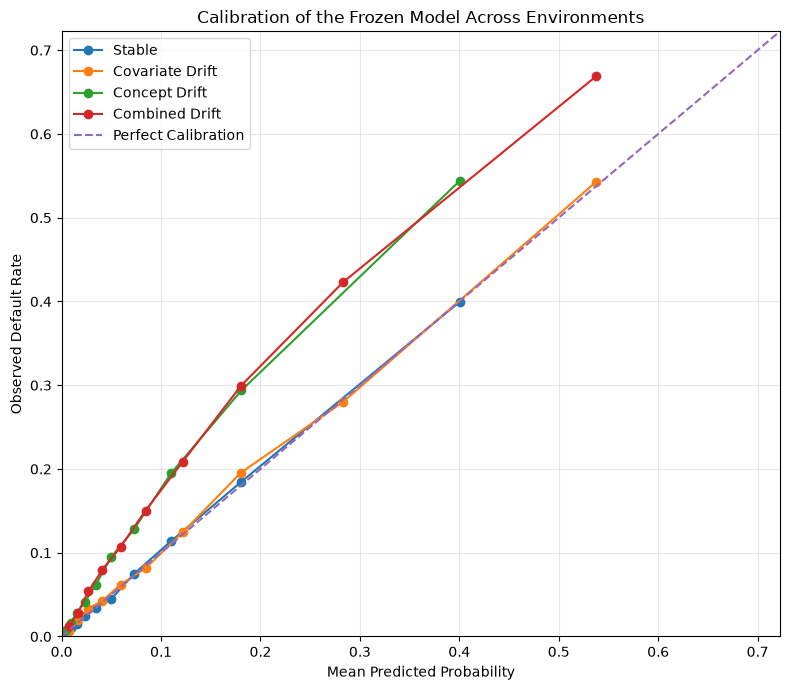

In [126]:
fig, ax = plt.subplots(
    figsize=(8, 7)
)

calibration_scenarios = {
    "Stable": stable_calibration,
    "Covariate Drift": covariate_calibration,
    "Concept Drift": concept_calibration,
    "Combined Drift": combined_calibration,
}

for (
    scenario_name,
    calibration_data,
) in calibration_scenarios.items():

    ax.plot(
        calibration_data["predicted_rate"],
        calibration_data["observed_rate"],
        marker="o",
        label=scenario_name,
    )

    all_calibration_values = np.concatenate(
    [
        calibration_data[
            [
                "predicted_rate",
                "observed_rate",
            ]
        ].to_numpy().ravel()
        for calibration_data
        in calibration_scenarios.values()
    ]
)

axis_max = min(
    1.0,
    all_calibration_values.max() * 1.08,
)

ax.plot(
    [0, axis_max],
    [0, axis_max],
    linestyle="--",
    label="Perfect Calibration",
)

ax.set_xlim(
    0,
    axis_max,
)

ax.set_ylim(
    0,
    axis_max,
)

ax.set_xlabel(
    "Mean Predicted Probability"
)

ax.set_ylabel(
    "Observed Default Rate"
)

ax.set_title(
    "Calibration of the Frozen Model Across Environments"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "calibration_by_scenario.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved figure to: {figure_path}"
)

plt.show()

## Progressive Concept Drift Over Time

The previous experiments compare distinct future environments.

We now extend the controlled concept-drift experiment across multiple monitoring periods.

The borrower feature observations are held fixed across all periods, so the empirical distribution of model inputs does not change.

The conditional outcome mechanism is gradually shifted by increasing the intercept of the true log-odds model over time.

Thus:

$
P_t(X) = P_0(X)
$

while:

$
P_t(Y \mid X)
$

moves progressively farther from the baseline relationship.

This provides a controlled representation of gradual model deterioration that may not be visible through input-distribution monitoring alone.

In [127]:
CONCEPT_DRIFT_PATH = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
]

In [128]:
temporal_base_features = stable_future[
    [
        "age",
        "annual_income",
        "credit_score",
        "debt_to_income",
        "loan_amount",
        "unemployment_rate",
        "loan_to_income",
    ]
].copy()

In [129]:
temporal_scenarios = []

In [130]:
for period, intercept_shift in enumerate(
    CONCEPT_DRIFT_PATH
):
    period_data = temporal_base_features.copy()

    period_data["period"] = period

    period_data["intercept_shift"] = (
        intercept_shift
    )

    period_data["true_pd"] = (
        calculate_concept_drift_true_pd(
            period_data,
            intercept_shift=intercept_shift,
        )
    )

    period_data["predicted_pd"] = (
        baseline_model.predict_proba(
            period_data[MODEL_FEATURES]
        )[:, 1]
    )

    temporal_scenarios.append(
        period_data
    )

In [131]:
temporal_environment = pd.concat(
    temporal_scenarios,
    ignore_index=True,
)

temporal_environment.shape

(350000, 11)

In [132]:
temporal_pd_summary = (
    temporal_environment
    .groupby(
        [
            "period",
            "intercept_shift",
        ],
        as_index=False,
    )
    .agg(
        true_pd_mean=(
            "true_pd",
            "mean",
        ),
        predicted_pd_mean=(
            "predicted_pd",
            "mean",
        ),
    )
)

In [133]:
temporal_pd_summary[
    "mean_pd_gap_pp"
] = (
    temporal_pd_summary[
        "predicted_pd_mean"
    ]
    - temporal_pd_summary[
        "true_pd_mean"
    ]
) * 100

In [134]:
temporal_pd_summary.round(4)

,period,intercept_shift,true_pd_mean,predicted_pd_mean,mean_pd_gap_pp
0,0,0.0,0.0923,0.0901,-0.2266
1,1,0.1,0.0993,0.0901,-0.9255
2,2,0.2,0.1067,0.0901,-1.6654
3,3,0.3,0.1145,0.0901,-2.4473
4,4,0.4,0.1228,0.0901,-3.2722
5,5,0.5,0.1315,0.0901,-4.1411
6,6,0.6,0.1406,0.0901,-5.0549


In [135]:
prediction_range = (
    temporal_pd_summary[
        "predicted_pd_mean"
    ].max()
    - temporal_pd_summary[
        "predicted_pd_mean"
    ].min()
)

print(
    f"Range of mean predicted PD "
    f"across periods: "
    f"{prediction_range}"
)

Range of mean predicted PD across periods: 0.0


In [136]:
assert np.isclose(
    prediction_range,
    0.0,
)

print(
    "Temporal frozen-model prediction "
    "check passed."
)

Temporal frozen-model prediction check passed.


In [137]:
true_pd_changes = (
    temporal_pd_summary[
        "true_pd_mean"
    ].diff().dropna()
)

assert (
    true_pd_changes > 0
).all()

print(
    "Progressive concept-drift "
    "true-PD check passed."
)

Progressive concept-drift true-PD check passed.


In [138]:
period_0_features = (
    temporal_environment.loc[
        temporal_environment["period"] == 0,
        MODEL_FEATURES,
    ]
    .reset_index(drop=True)
)

period_6_features = (
    temporal_environment.loc[
        temporal_environment["period"] == 6,
        MODEL_FEATURES,
    ]
    .reset_index(drop=True)
)

temporal_features_identical = (
    np.array_equal(
        period_0_features.to_numpy(),
        period_6_features.to_numpy(),
    )
)

print(
    f"Period 0 vs. Period 6 "
    f"feature values identical: "
    f"{temporal_features_identical}"
)

Period 0 vs. Period 6 feature values identical: True


In [139]:
assert temporal_features_identical

print(
    "Temporal input-distribution "
    "check passed."
)

Temporal input-distribution check passed.


In [140]:
temporal_evaluated_scenarios = []

In [141]:
for period, intercept_shift in enumerate(
    CONCEPT_DRIFT_PATH
):
    period_data = (
        temporal_environment.loc[
            temporal_environment["period"]
            == period
        ]
        .copy()
        .reset_index(drop=True)
    )

    period_rng = np.random.default_rng(
        RANDOM_SEED + 100 + period
    )

    period_data["default"] = (
        generate_observed_defaults(
            true_pd=period_data["true_pd"],
            rng=period_rng,
        )
    )

    temporal_evaluated_scenarios.append(
        period_data
    )

In [142]:
temporal_evaluated = pd.concat(
    temporal_evaluated_scenarios,
    ignore_index=True,
)

temporal_evaluated.shape

(350000, 12)

In [143]:
temporal_results_list = []

In [144]:
for period, intercept_shift in enumerate(
    CONCEPT_DRIFT_PATH
):
    period_data = temporal_evaluated.loc[
        temporal_evaluated["period"]
        == period
    ]

    period_results = evaluate_scenario(
        data=period_data,
        scenario_name=f"Period {period}",
    )

    period_results["period"] = period
    period_results[
        "intercept_shift"
    ] = intercept_shift

    temporal_results_list.append(
        period_results
    )

In [145]:
temporal_results = pd.concat(
    temporal_results_list,
    ignore_index=True,
)

In [146]:
temporal_results[
    [
        "period",
        "intercept_shift",
        "true_pd_mean",
        "observed_default_rate",
        "predicted_pd_mean",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,period,intercept_shift,true_pd_mean,observed_default_rate,predicted_pd_mean,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,0,0.0,0.0923,0.0920,0.0901,0.8344,0.0680,0.2372,0.0023,0.0023
1,1,0.1,0.0993,0.0991,0.0901,0.8368,0.0717,0.2474,0.0090,0.0093
2,2,0.2,0.1067,0.1063,0.0901,0.8348,0.0764,0.2613,0.0162,0.0167
3,3,0.3,0.1145,0.1159,0.0901,0.8310,0.0827,0.2803,0.0259,0.0245
4,4,0.4,0.1228,0.1252,0.0901,0.8336,0.0878,0.2954,0.0352,0.0327
5,5,0.5,0.1315,0.1305,0.0901,0.8268,0.0923,0.3097,0.0404,0.0414
6,6,0.6,0.1406,0.1407,0.0901,0.8299,0.0982,0.3269,0.0506,0.0505


In [147]:
temporal_results[
    "mean_pd_gap_pp"
] = (
    temporal_results[
        "predicted_pd_mean"
    ]
    - temporal_results[
        "true_pd_mean"
    ]
) * 100

In [148]:
temporal_results[
    [
        "period",
        "intercept_shift",
        "mean_pd_gap_pp",
        "roc_auc",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,period,intercept_shift,mean_pd_gap_pp,roc_auc,calibration_error,mae_vs_true_pd
0,0,0.0,-0.2266,0.8344,0.0023,0.0023
1,1,0.1,-0.9255,0.8368,0.0090,0.0093
2,2,0.2,-1.6654,0.8348,0.0162,0.0167
3,3,0.3,-2.4473,0.8310,0.0259,0.0245
4,4,0.4,-3.2722,0.8336,0.0352,0.0327
5,5,0.5,-4.1411,0.8268,0.0404,0.0414
6,6,0.6,-5.0549,0.8299,0.0506,0.0505


In [149]:
mae_changes = (
    temporal_results[
        "mae_vs_true_pd"
    ].diff().dropna()
)

assert (
    mae_changes > 0
).all()

print(
    "Temporal true-PD error "
    "increases monotonically."
)

Temporal true-PD error increases monotonically.


In [150]:
temporal_endpoint_drift = (
    summarize_feature_drift(
        reference_data=(
            temporal_evaluated.loc[
                temporal_evaluated["period"]
                == 0
            ]
        ),
        current_data=(
            temporal_evaluated.loc[
                temporal_evaluated["period"]
                == 6
            ]
        ),
        features=MODEL_FEATURES,
    )
)

temporal_endpoint_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,699.7566,0.0,0.0,0.0,0.0
1,debt_to_income,0.3337,0.3337,0.0,0.0,0.0,0.0
2,loan_to_income,0.3239,0.3239,0.0,0.0,0.0,0.0
3,unemployment_rate,0.0450,0.0450,0.0,0.0,0.0,0.0


In [151]:
assert np.allclose(
    temporal_endpoint_drift["psi"],
    0.0,
)

assert np.allclose(
    temporal_endpoint_drift[
        "ks_statistic"
    ],
    0.0,
)

print(
    "Temporal endpoint input-drift "
    "check passed."
)

Temporal endpoint input-drift check passed.


### Progressive Deterioration Interpretation

The temporal experiment holds model inputs fixed while gradually changing the conditional outcome mechanism.

As the concept shift increases, the frozen model's probability estimates move progressively farther from the synthetic true probabilities.

Input-distribution monitoring remains unchanged because the model receives the same feature observations in every period.

This experiment separates gradual concept deterioration from conventional covariate drift and allows the responsiveness of different monitoring metrics to be compared over time.

In [152]:
temporal_plot_data = temporal_results[
    [
        "period",
        "intercept_shift",
        "true_pd_mean",
        "predicted_pd_mean",
    ]
].copy()

In [153]:
temporal_plot_data[
    "true_pd_percent"
] = (
    temporal_plot_data["true_pd_mean"]
    * 100
)

temporal_plot_data[
    "predicted_pd_percent"
] = (
    temporal_plot_data["predicted_pd_mean"]
    * 100
)

temporal_plot_data.round(2)

,period,intercept_shift,true_pd_mean,predicted_pd_mean,true_pd_percent,predicted_pd_percent
0,0,0.0,0.09,0.09,9.23,9.01
1,1,0.1,0.10,0.09,9.93,9.01
2,2,0.2,0.11,0.09,10.67,9.01
3,3,0.3,0.11,0.09,11.45,9.01
4,4,0.4,0.12,0.09,12.28,9.01
5,5,0.5,0.13,0.09,13.15,9.01
6,6,0.6,0.14,0.09,14.06,9.01


Saved figure to: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\progressive_concept_drift_pd.png


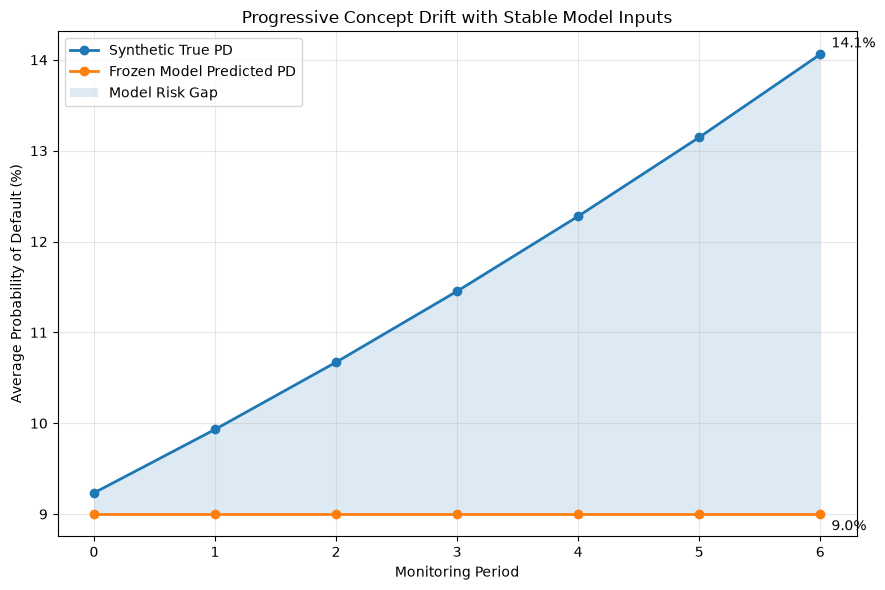

In [154]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    temporal_plot_data["period"],
    temporal_plot_data[
        "true_pd_percent"
    ],
    marker="o",
    linewidth=2,
    label="Synthetic True PD",
)

ax.plot(
    temporal_plot_data["period"],
    temporal_plot_data[
        "predicted_pd_percent"
    ],
    marker="o",
    linewidth=2,
    label="Frozen Model Predicted PD",
)

ax.fill_between(
    temporal_plot_data["period"],
    temporal_plot_data[
        "predicted_pd_percent"
    ],
    temporal_plot_data[
        "true_pd_percent"
    ],
    alpha=0.15,
    label="Model Risk Gap",
)

final_row = temporal_plot_data.iloc[-1]

ax.annotate(
    f"{final_row['true_pd_percent']:.1f}%",
    (
        final_row["period"],
        final_row["true_pd_percent"],
    ),
    xytext=(8, 5),
    textcoords="offset points",
)

ax.annotate(
    f"{final_row['predicted_pd_percent']:.1f}%",
    (
        final_row["period"],
        final_row["predicted_pd_percent"],
    ),
    xytext=(8, -12),
    textcoords="offset points",
)

ax.set_xlabel(
    "Monitoring Period"
)

ax.set_ylabel(
    "Average Probability of Default (%)"
)

ax.set_title(
    "Progressive Concept Drift with Stable Model Inputs"
)

ax.set_xticks(
    temporal_plot_data["period"]
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

figure_path = (
    FIGURES_DIR
    / "progressive_concept_drift_pd.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved figure to: {figure_path}"
)

plt.show()

In [155]:
temporal_reference = (
    temporal_evaluated.loc[
        temporal_evaluated["period"] == 0
    ]
    .copy()
)

In [156]:
temporal_drift_rows = []

for period in temporal_results["period"]:
    current_period = (
        temporal_evaluated.loc[
            temporal_evaluated["period"]
            == period
        ]
    )

    drift_table = summarize_feature_drift(
        reference_data=temporal_reference,
        current_data=current_period,
        features=MODEL_FEATURES,
    )

    temporal_drift_rows.append(
        {
            "period": period,
            "max_psi": drift_table[
                "psi"
            ].max(),
            "max_ks": drift_table[
                "ks_statistic"
            ].max(),
        }
    )

temporal_drift_summary = pd.DataFrame(
    temporal_drift_rows
)

temporal_drift_summary.round(4)

,period,max_psi,max_ks
0,0,0.0,0.0
1,1,0.0,0.0
2,2,0.0,0.0
3,3,0.0,0.0
4,4,0.0,0.0
5,5,0.0,0.0
6,6,0.0,0.0


In [157]:
temporal_monitoring_summary = pd.merge(
    temporal_results,
    temporal_drift_summary,
    on="period",
    how="left",
)

In [158]:
temporal_monitoring_summary[
    [
        "period",
        "intercept_shift",
        "max_psi",
        "max_ks",
        "roc_auc",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,period,intercept_shift,max_psi,max_ks,roc_auc,calibration_error,mae_vs_true_pd
0,0,0.0,0.0,0.0,0.8344,0.0023,0.0023
1,1,0.1,0.0,0.0,0.8368,0.0090,0.0093
2,2,0.2,0.0,0.0,0.8348,0.0162,0.0167
3,3,0.3,0.0,0.0,0.8310,0.0259,0.0245
4,4,0.4,0.0,0.0,0.8336,0.0352,0.0327
5,5,0.5,0.0,0.0,0.8268,0.0404,0.0414
6,6,0.6,0.0,0.0,0.8299,0.0506,0.0505


In [159]:
assert np.allclose(
    temporal_monitoring_summary[
        "max_psi"
    ],
    0.0,
)

assert np.allclose(
    temporal_monitoring_summary[
        "max_ks"
    ],
    0.0,
)

print(
    "Temporal input-drift metrics "
    "remain zero across all periods."
)

Temporal input-drift metrics remain zero across all periods.


Saved figure to: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\progressive_monitoring_signals.png


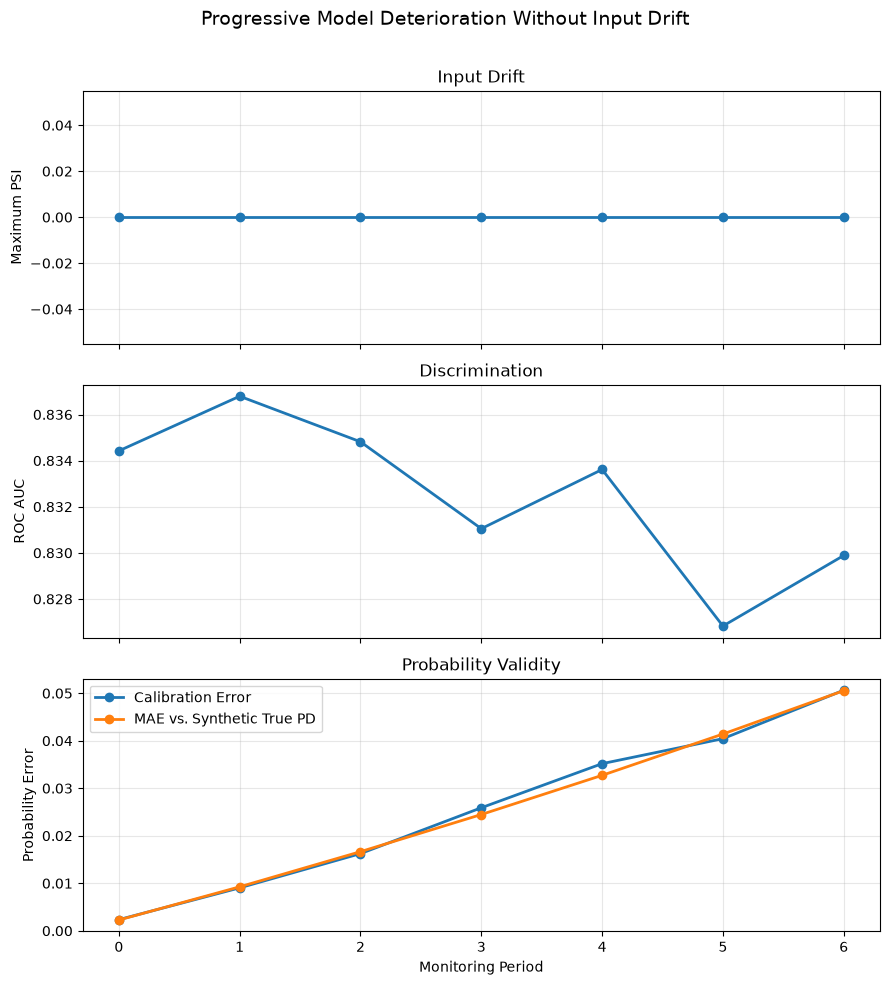

In [160]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(9, 10),
    sharex=True,
)

axes[0].plot(
    temporal_monitoring_summary["period"],
    temporal_monitoring_summary["max_psi"],
    marker="o",
    linewidth=2,
)

axes[0].set_ylabel(
    "Maximum PSI"
)

axes[0].set_title(
    "Input Drift"
)

axes[0].grid(
    alpha=0.3
)

axes[1].plot(
    temporal_monitoring_summary["period"],
    temporal_monitoring_summary["roc_auc"],
    marker="o",
    linewidth=2,
)

axes[1].set_ylabel(
    "ROC AUC"
)

axes[1].set_title(
    "Discrimination"
)

axes[1].grid(
    alpha=0.3
)

axes[2].plot(
    temporal_monitoring_summary["period"],
    temporal_monitoring_summary[
        "calibration_error"
    ],
    marker="o",
    linewidth=2,
    label="Calibration Error",
)

axes[2].plot(
    temporal_monitoring_summary["period"],
    temporal_monitoring_summary[
        "mae_vs_true_pd"
    ],
    marker="o",
    linewidth=2,
    label="MAE vs. Synthetic True PD",
)

axes[2].set_xlabel(
    "Monitoring Period"
)

axes[2].set_ylabel(
    "Probability Error"
)

axes[2].set_title(
    "Probability Validity"
)

axes[2].legend()

axes[2].grid(
    alpha=0.3
)

axes[2].set_xticks(
    temporal_monitoring_summary["period"]
)

fig.suptitle(
    "Progressive Model Deterioration Without Input Drift",
    fontsize=14,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

figure_path = (
    FIGURES_DIR
    / "progressive_monitoring_signals.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved figure to: {figure_path}"
)

plt.show()

## Economic Shock / Regime-Change Scenario

The previous scenarios isolate generic forms of covariate and concept drift.

This scenario represents a more economically interpretable regime change.

The experiment assumes that:

1. unemployment rates increase materially relative to the Stable environment; and
2. default risk becomes more sensitive to unemployment than it was under the baseline data-generating process.

Thus, both the input distribution and the conditional outcome mechanism change:

$
P_t(X) \neq P_0(X)
$

and:

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

Unlike the earlier Concept Drift experiment, which changed only the intercept of the true log-odds model, this regime-change scenario modifies a feature coefficient. Therefore, it can potentially affect both probability calibration and borrower risk ranking.

In [161]:
ECONOMIC_SHOCK_UNEMPLOYMENT_SHIFT = 0.020

BASELINE_UNEMPLOYMENT_COEFFICIENT = 0.45

SHOCK_UNEMPLOYMENT_COEFFICIENT = 0.75

In [162]:
economic_shock_future = stable_future[
    [
        "age",
        "annual_income",
        "credit_score",
        "debt_to_income",
        "loan_amount",
        "unemployment_rate",
        "loan_to_income",
    ]
].copy()

In [163]:
economic_shock_future[
    "unemployment_rate"
] = np.clip(
    economic_shock_future[
        "unemployment_rate"
    ]
    + ECONOMIC_SHOCK_UNEMPLOYMENT_SHIFT,
    0.025,
    0.120,
)

In [164]:
stable_unemployment_mean = (
    stable_future[
        "unemployment_rate"
    ].mean()
)

shock_unemployment_mean = (
    economic_shock_future[
        "unemployment_rate"
    ].mean()
)

unemployment_shift = (
    shock_unemployment_mean
    - stable_unemployment_mean
)

print(
    f"Stable mean unemployment rate: "
    f"{stable_unemployment_mean:.4%}"
)

print(
    f"Shock mean unemployment rate: "
    f"{shock_unemployment_mean:.4%}"
)

print(
    f"Mean unemployment-rate shift: "
    f"{unemployment_shift:.4%}"
)

Stable mean unemployment rate: 4.4989%
Shock mean unemployment rate: 6.4989%
Mean unemployment-rate shift: 2.0000%


In [165]:
def calculate_economic_shock_true_pd(
    borrowers,
    unemployment_coefficient=(
        SHOCK_UNEMPLOYMENT_COEFFICIENT
    ),
):
    """
    Calculate true PD under an economic regime change.

    The baseline relationships are retained except that
    default risk becomes more sensitive to unemployment.

    Parameters
    ----------
    borrowers : pandas.DataFrame
        Borrower characteristics under the shock environment.

    unemployment_coefficient : float
        True coefficient applied to the standardized
        unemployment-rate effect.

    Returns
    -------
    pandas.Series
        True probability of default under the shock regime.
    """

    credit_score_effect = (
        borrowers["credit_score"] - 700
    ) / 50

    dti_effect = (
        borrowers["debt_to_income"] - 0.33
    ) / 0.15

    loan_burden_effect = (
        borrowers["loan_to_income"] - 0.30
    ) / 0.15

    unemployment_effect = (
        borrowers["unemployment_rate"] - 0.045
    ) / 0.01

    log_odds = (
        -3.2
        - 0.65 * credit_score_effect
        + 1.00 * dti_effect
        + 0.65 * loan_burden_effect
        + unemployment_coefficient
        * unemployment_effect
    )

    true_pd = 1 / (
        1 + np.exp(-log_odds)
    )

    return true_pd

In [166]:
economic_shock_future[
    "baseline_relationship_pd"
] = (
    calculate_baseline_true_pd(
        economic_shock_future
    )
)

In [167]:
economic_shock_future[
    "true_pd"
] = (
    calculate_economic_shock_true_pd(
        economic_shock_future
    )
)

In [168]:
print(
    f"Stable average true PD: "
    f"{stable_future['true_pd'].mean():.4%}"
)

print(
    f"Shock PD under baseline relationship: "
    f"{economic_shock_future['baseline_relationship_pd'].mean():.4%}"
)

print(
    f"Shock PD under changed relationship: "
    f"{economic_shock_future['true_pd'].mean():.4%}"
)

Stable average true PD: 9.2327%
Shock PD under baseline relationship: 17.0769%
Shock PD under changed relationship: 24.5625%


In [169]:
additional_regime_effect = (
    economic_shock_future["true_pd"]
    - economic_shock_future[
        "baseline_relationship_pd"
    ]
)

print(
    f"Average additional PD from "
    f"relationship change: "
    f"{additional_regime_effect.mean():.4%}"
)

Average additional PD from relationship change: 7.4856%


In [170]:
economic_shock_rng = (
    np.random.default_rng(
        RANDOM_SEED + 5
    )
)

In [171]:
economic_shock_future[
    "default"
] = generate_observed_defaults(
    true_pd=economic_shock_future[
        "true_pd"
    ],
    rng=economic_shock_rng,
)

In [172]:
economic_shock_future[
    "predicted_pd"
] = (
    baseline_model.predict_proba(
        economic_shock_future[
            MODEL_FEATURES
        ]
    )[:, 1]
)

In [173]:
print(
    f"Average true PD: "
    f"{economic_shock_future['true_pd'].mean():.4%}"
)

print(
    f"Observed default rate: "
    f"{economic_shock_future['default'].mean():.4%}"
)

print(
    f"Average predicted PD: "
    f"{economic_shock_future['predicted_pd'].mean():.4%}"
)

Average true PD: 24.5625%
Observed default rate: 24.5700%
Average predicted PD: 16.6422%


In [174]:
shock_feature_comparison = pd.DataFrame(
    {
        "Stable Mean": stable_future[
            MODEL_FEATURES
        ].mean(),
        "Economic Shock Mean":
            economic_shock_future[
                MODEL_FEATURES
            ].mean(),
    }
)

shock_feature_comparison[
    "Difference"
] = (
    shock_feature_comparison[
        "Economic Shock Mean"
    ]
    - shock_feature_comparison[
        "Stable Mean"
    ]
)

shock_feature_comparison.round(4)

,Stable Mean,Economic Shock Mean,Difference
credit_score,699.7566,699.7566,0.00
debt_to_income,0.3337,0.3337,0.00
loan_to_income,0.3239,0.3239,0.00
unemployment_rate,0.0450,0.0650,0.02


In [175]:
assert len(
    economic_shock_future
) == N_FUTURE

assert economic_shock_future[
    "true_pd"
].between(
    0, 1
).all()

assert economic_shock_future[
    "predicted_pd"
].between(
    0, 1
).all()

assert (
    economic_shock_future[
        "true_pd"
    ]
    >
    economic_shock_future[
        "baseline_relationship_pd"
    ]
).all()

unchanged_features = [
    "credit_score",
    "debt_to_income",
    "loan_to_income",
]

for feature in unchanged_features:
    assert np.array_equal(
        stable_future[feature].to_numpy(),
        economic_shock_future[
            feature
        ].to_numpy(),
    )

print(
    "Economic shock scenario checks passed."
)

Economic shock scenario checks passed.


In [176]:
economic_shock_results = evaluate_scenario(
    data=economic_shock_future,
    scenario_name="Economic Shock",
)

economic_shock_results[
    [
        "scenario",
        "roc_auc",
        "brier_score",
        "log_loss",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,roc_auc,brier_score,log_loss,calibration_error,mae_vs_true_pd
0,Economic Shock,0.8241,0.1438,0.4475,0.0793,0.0792


In [177]:
economic_shock_input_drift = (
    summarize_feature_drift(
        reference_data=stable_future,
        current_data=economic_shock_future,
        features=MODEL_FEATURES,
    )
)

economic_shock_input_drift.round(4)

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.7566,699.7566,0.00,0.0000,0.0000,0.00
1,debt_to_income,0.3337,0.3337,0.00,0.0000,0.0000,0.00
2,loan_to_income,0.3239,0.3239,0.00,0.0000,0.0000,0.00
3,unemployment_rate,0.0450,0.0650,0.02,10.0183,0.9513,0.02


In [178]:
economic_shock_drift_summary = (
    summarize_scenario_input_drift(
        economic_shock_input_drift,
        "Economic Shock",
    )
)

economic_shock_drift_summary.round(4)

,scenario,max_psi,mean_psi,max_ks,mean_ks
0,Economic Shock,10.0183,2.5046,0.9513,0.2378


In [179]:
economic_shock_results[
    "mean_pd_gap_pp"
] = (
    economic_shock_results[
        "predicted_pd_mean"
    ]
    - economic_shock_results[
        "true_pd_mean"
    ]
) * 100

In [180]:
economic_shock_results[
    [
        "scenario",
        "true_pd_mean",
        "observed_default_rate",
        "predicted_pd_mean",
        "mean_pd_gap_pp",
    ]
].round(4)

,scenario,true_pd_mean,observed_default_rate,predicted_pd_mean,mean_pd_gap_pp
0,Economic Shock,0.2456,0.2457,0.1664,-7.9203


In [181]:
mae_vs_old_regime_truth = np.mean(
    np.abs(
        economic_shock_future[
            "predicted_pd"
        ]
        - economic_shock_future[
            "baseline_relationship_pd"
        ]
    )
)

mae_vs_new_regime_truth = np.mean(
    np.abs(
        economic_shock_future[
            "predicted_pd"
        ]
        - economic_shock_future[
            "true_pd"
        ]
    )
)

print(
    f"MAE vs. old-regime PD: "
    f"{mae_vs_old_regime_truth:.4f}"
)

print(
    f"MAE vs. new-regime PD: "
    f"{mae_vs_new_regime_truth:.4f}"
)

MAE vs. old-regime PD: 0.0043
MAE vs. new-regime PD: 0.0792


In [182]:
structural_regime_gap = np.mean(
    np.abs(
        economic_shock_future[
            "true_pd"
        ]
        - economic_shock_future[
            "baseline_relationship_pd"
        ]
    )
)

print(
    f"Average structural regime gap: "
    f"{structural_regime_gap:.4f}"
)

Average structural regime gap: 0.0749


In [183]:
extended_scenario_results = pd.concat(
    [
        scenario_results,
        economic_shock_results,
    ],
    ignore_index=True,
)

In [184]:
extended_drift_summary = pd.concat(
    [
        scenario_drift_summary,
        economic_shock_drift_summary,
    ],
    ignore_index=True,
)

In [185]:
extended_monitoring_summary = pd.merge(
    extended_drift_summary,
    extended_scenario_results,
    on="scenario",
    how="inner",
)

In [186]:
extended_monitoring_summary[
    "mean_pd_gap_pp"
] = (
    extended_monitoring_summary[
        "predicted_pd_mean"
    ]
    - extended_monitoring_summary[
        "true_pd_mean"
    ]
) * 100

In [187]:
extended_monitoring_summary[
    [
        "scenario",
        "max_psi",
        "max_ks",
        "true_pd_mean",
        "predicted_pd_mean",
        "mean_pd_gap_pp",
        "roc_auc",
        "calibration_error",
        "mae_vs_true_pd",
    ]
].round(4)

,scenario,max_psi,max_ks,true_pd_mean,predicted_pd_mean,mean_pd_gap_pp,roc_auc,calibration_error,mae_vs_true_pd
0,Stable,0.0000,0.0000,0.0923,0.0901,-0.2266,0.8383,0.0019,0.0023
1,Covariate Drift,0.1204,0.1418,0.1387,0.1358,-0.2892,0.8300,0.0043,0.0029
2,Concept Drift,0.0000,0.0000,0.1406,0.0901,-5.0549,0.8316,0.0511,0.0505
3,Combined Drift,0.1204,0.1418,0.2024,0.1358,-6.6506,0.8237,0.0673,0.0665
4,Economic Shock,10.0183,0.9513,0.2456,0.1664,-7.9203,0.8241,0.0793,0.0792


### Economic Regime-Change Interpretation

The Economic Shock scenario differs from the earlier generic Concept Drift experiment in two ways.

First, the operating population changes because unemployment rates increase, creating clear covariate drift.

Second, the true relationship between unemployment and default becomes stronger. The frozen model responds to the observed increase in unemployment, but it continues to use the relationship learned under the original regime.

The scenario therefore distinguishes between a model encountering unusual input values and a deeper structural change in how those values relate to the outcome.

Input-drift monitoring can identify that the economic environment has changed, but input drift alone cannot determine whether the original conditional model remains valid.

In [188]:
assert economic_shock_results.shape[0] == 1

assert (
    economic_shock_results.loc[
        0,
        "scenario",
    ]
    == "Economic Shock"
)

assert len(
    extended_monitoring_summary
) == 5

assert (
    economic_shock_input_drift.loc[
        economic_shock_input_drift[
            "feature"
        ] == "credit_score",
        "psi",
    ].iloc[0]
    == 0.0
)

assert (
    economic_shock_input_drift.loc[
        economic_shock_input_drift[
            "feature"
        ] == "unemployment_rate",
        "psi",
    ].iloc[0]
    > 0.0
)

print(
    "Economic shock evaluation checks passed."
)

Economic shock evaluation checks passed.


## Key Findings

The controlled experiments demonstrate that input drift, model deterioration, discrimination, and calibration are related but distinct aspects of model risk.

### 1. Input drift does not necessarily imply model deterioration

The Covariate Drift scenario intentionally changed the borrower population by lowering credit scores and increasing debt-to-income ratios.

Input-monitoring statistics clearly detected the change:

- maximum PSI: approximately 0.12;
- maximum KS statistic: approximately 0.14.

However, the underlying relationship $P(Y \mid X)$ was unchanged.

The frozen model continued to approximate the known synthetic true probabilities closely, with MAE versus true PD increasing only slightly relative to the Stable environment.

Therefore, substantial movement in $P(X)$ does not by itself establish that a model has become invalid.

### 2. Model deterioration can occur without input drift

The Concept Drift scenario used exactly the same model-input observations as the Stable environment.

Consequently:

$
P_t(X) = P_0(X)
$

within the controlled sample, and the measured PSI, KS statistic, and Wasserstein distance were all zero.

Nevertheless, the conditional default mechanism changed:

$
P_t(Y \mid X) \neq P_0(Y \mid X).
$

The frozen model continued to produce exactly the same predictions, while average synthetic true default probability increased from approximately 9.2% to 14.1%.

Calibration error increased from approximately 0.002 to 0.051, while MAE versus synthetic true PD increased from approximately 0.002 to 0.051.

Therefore, stable model inputs do not guarantee continued model validity.

### 3. Similar input-drift signals can correspond to very different model-risk states

Covariate Drift and Combined Drift use exactly the same input observations and therefore produce identical input-drift statistics.

However, their model-validity outcomes differ substantially.

Under Covariate Drift, MAE versus true PD remains approximately 0.003.

Under Combined Drift, where $P(Y \mid X)$ also changes, MAE rises to approximately 0.067.

Thus, observing the magnitude of input drift alone is insufficient to determine whether the model's conditional relationship remains valid.

### 4. Discrimination can remain relatively stable while calibration deteriorates

ROC AUC remains in a relatively narrow range across the main controlled environments even when probability accuracy deteriorates materially.

In the Concept Drift experiment, the model continues to rank borrowers reasonably well while systematically underestimating their absolute probability of default.

This demonstrates that:

$
\text{stable discrimination}
\not\Rightarrow
\text{stable calibration}.
$

Monitoring discrimination alone can therefore miss economically meaningful deterioration in probability estimates.

### 5. Concept deterioration can emerge gradually

The progressive concept-drift experiment holds the model inputs fixed over multiple monitoring periods while gradually changing the true conditional outcome mechanism.

Input-drift measures remain zero and ROC AUC remains relatively stable.

Meanwhile, MAE versus synthetic true PD increases monotonically from approximately 0.002 to 0.051, and calibration error rises similarly.

This illustrates how a deployed model can become progressively stale even when conventional input monitoring continues to indicate stability.

### 6. Regime change can make an old relationship invalid even when the model reacts to changing inputs

The Economic Shock scenario increases unemployment by approximately two percentage points and simultaneously increases the true sensitivity of default risk to unemployment.

The frozen model reacts to the higher unemployment values and raises its average predicted probability of default.

However, it continues to apply the relationship learned under the original regime.

Under the hypothetical assumption that the old relationship remained valid, the model's MAE relative to the synthetic truth is approximately 0.004.

Under the new regime, MAE rises to approximately 0.079.

The majority of the resulting model error therefore comes from structural change in $P(Y \mid X)$, rather than merely from observing a higher-unemployment population.

The unemployment shift in this scenario is intentionally severe and produces extremely large synthetic input-drift statistics. It should be interpreted as a controlled stress experiment rather than as a representative production PSI level.

## Implications for Adaptive Model Risk

These experiments support a monitoring framework that distinguishes among at least three questions:

1. **Has the operating population changed?**

   This concerns changes in $P(X)$ and can be monitored using distributional statistics such as PSI, KS, or Wasserstein distance.

2. **Does the model still discriminate effectively?**

   This concerns ranking performance and can be monitored using measures such as ROC AUC when sufficiently mature outcomes are available.

3. **Does the model still represent the current relationship between inputs and outcomes?**

   This concerns $P(Y \mid X)$, calibration, and probability accuracy.

No single category of metric answers all three questions.

In particular:

$
\text{input stability}
\not\Rightarrow
\text{model validity}
$

and:

$
\text{input drift}
\not\Rightarrow
\text{model failure}.
$

A robust model-monitoring framework should therefore combine signals from input distributions, realized model performance, probability calibration, and changing relationships between predictors and outcomes.

The synthetic credit-risk environment in this notebook is a controlled experimental setting for demonstrating these broader model-risk principles. It is not intended to represent a production credit-risk model or to prescribe universal monitoring thresholds.